In [1]:

# PHASE 0 — Environment setup
# Run this before downloading or processing any data.

import sys
import os
import json
import importlib.util
import subprocess
from pathlib import Path
from datetime import datetime, timezone

required_packages = {
    "gwpy": "gwpy",
    "pycbc": "pycbc",
    "gwosc": "gwosc",
    "h5py": "h5py",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "pandas": "pandas",
}

missing_packages = [
    package
    for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

print("Missing packages:", missing_packages or "None")

if missing_packages:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        *missing_packages
    ])

# Create a clean project structure.
PROJECT_DIR = Path("/content/gw150914_flagship")

folders = [
    "raw",
    "processed",
    "figures",
    "models",
    "reports",
    "logs",
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

# Verify imports and record software versions.
import numpy as np
import scipy
import matplotlib
import pandas as pd
import gwpy
import pycbc
import gwosc
import h5py
import sklearn

environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "pandas": pd.__version__,
    "gwpy": gwpy.__version__,
    "pycbc": pycbc.__version__,
    "gwosc": getattr(gwosc, "__version__", "not exposed"),
    "h5py": h5py.__version__,
    "scikit_learn": sklearn.__version__,
}

with open(PROJECT_DIR / "logs" / "environment.json", "w") as f:
    json.dump(environment, f, indent=2)

print("\nProject directory:", PROJECT_DIR)
print("\nEnvironment verification:")
for package, version in environment.items():
    print(f"{package}: {version}")

print("\nPHASE 0 COMPLETE")
print("Environment record saved.")


Missing packages: ['gwpy', 'pycbc', 'gwosc']


/usr/local/lib/python3.13/dist-packages/gwpy/time/_ligotimegps.py:42: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS



Project directory: /content/gw150914_flagship

Environment verification:
created_utc: 2026-10-27T12:13:31.329348+00:00
python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
numpy: 2.1.3
scipy: 1.16.3
matplotlib: 3.10.0
pandas: 2.2.3
gwpy: 4.1.0
pycbc: 2.11.0
gwosc: 0.8.3
h5py: 3.14.0
scikit_learn: 1.6.1

PHASE 0 COMPLETE
Environment record saved.


In [2]:

# PHASE 1A — Download the GW150914 event data
# Official public data through GWOSC using GWpy.

import json
import numpy as np
from pathlib import Path
from gwpy.timeseries import TimeSeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"

# GW150914 event GPS time
EVENT_GPS = 1126259462.4
SAMPLE_RATE = 4096
HALF_DURATION = 16

START_GPS = EVENT_GPS - HALF_DURATION
END_GPS = EVENT_GPS + HALF_DURATION

event_data = {}
manifest = {
    "event": "GW150914",
    "event_gps": EVENT_GPS,
    "requested_start_gps": START_GPS,
    "requested_end_gps": END_GPS,
    "requested_sample_rate_hz": SAMPLE_RATE,
    "source": "GWOSC public strain data via GWpy",
    "detectors": {}
}

for detector in ["H1", "L1"]:
    print(f"\nDownloading {detector}...")

    try:
        strain = TimeSeries.fetch_open_data(
            detector,
            START_GPS,
            END_GPS,
            sample_rate=SAMPLE_RATE,
            cache=True
        )

        values = np.asarray(strain.value, dtype=np.float64)

        # Verify the returned data before saving.
        assert len(values) > 0, f"{detector}: empty data"
        assert np.isfinite(values).all(), (
            f"{detector}: non-finite samples found"
        )

        actual_rate = float(strain.sample_rate.value)
        actual_start = float(strain.t0.value)
        actual_end = float(strain.times.value[-1])

        # Save unfiltered strain, with metadata.
        np.save(RAW_DIR / f"{detector}_GW150914_raw.npy", values)

        event_data[detector] = strain

        manifest["detectors"][detector] = {
            "sample_count": int(len(values)),
            "sample_rate_hz": actual_rate,
            "start_gps": actual_start,
            "last_sample_gps": actual_end,
            "duration_seconds": float(len(values) / actual_rate),
            "finite_values": True,
            "standard_deviation": float(np.std(values)),
            "raw_file": f"{detector}_GW150914_raw.npy"
        }

        print("Download and basic validation successful.")
        print("Samples:", len(values))
        print("Sampling rate:", actual_rate, "Hz")
        print("Start GPS:", actual_start)
        print("Last sample GPS:", actual_end)
        print("Standard deviation:", np.std(values))

    except Exception as exc:
        print(f"{detector} DOWNLOAD/VALIDATION FAILED")
        print(type(exc).__name__, str(exc))
        raise

with open(REPORT_DIR / "GW150914_event_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("\nPHASE 1A COMPLETE")
print("Raw files saved in:", RAW_DIR)
print("Manifest saved in:", REPORT_DIR)
print("Do not filter or overwrite the raw files.")



Download and basic validation successful.
Samples: 131072
Sampling rate: 4096.0 Hz
Start GPS: 1126259446.3999023
Last sample GPS: 1126259478.3996582
Standard deviation: 2.2158934597034714e-19

Download and basic validation successful.
Samples: 131072
Sampling rate: 4096.0 Hz
Start GPS: 1126259446.3999023
Last sample GPS: 1126259478.3996582
Standard deviation: 2.3277355999658365e-19

PHASE 1A COMPLETE
Raw files saved in: /content/gw150914_flagship/raw
Manifest saved in: /content/gw150914_flagship/reports
Do not filter or overwrite the raw files.


In [3]:

# PHASE 1B — Download independent candidate background segments
# Preserve raw strain. Do not filter or whiten it here.

import json
import numpy as np
from pathlib import Path
from gwpy.timeseries import TimeSeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"

EVENT_GPS = 1126259462.4
SAMPLE_RATE = 4096
SEGMENT_DURATION = 128

# Each number is the time separation, in seconds, between
# the event GPS time and the CENTER of a candidate segment.
OFFSETS_SECONDS = [300, 600, 900, 1200]

background_manifest = {
    "event": "GW150914",
    "source": "GWOSC public strain data via GWpy",
    "sample_rate_hz_requested": SAMPLE_RATE,
    "segment_duration_seconds_requested": SEGMENT_DURATION,
    "selection_note": (
        "Candidate off-source periods. Not yet certified glitch-free "
        "or confirmed suitable for training."
    ),
    "segments": []
}

for offset in OFFSETS_SECONDS:
    center_gps = EVENT_GPS - offset
    start_gps = center_gps - SEGMENT_DURATION / 2
    end_gps = center_gps + SEGMENT_DURATION / 2

    print(
        f"\nCandidate offset: {offset}s | "
        f"GPS interval: {start_gps:.3f} to {end_gps:.3f}"
    )

    record = {
        "offset_before_event_seconds": offset,
        "requested_start_gps": start_gps,
        "requested_end_gps": end_gps,
        "detectors": {}
    }

    for detector in ["H1", "L1"]:
        print(f"  Downloading {detector}...")

        strain = TimeSeries.fetch_open_data(
            detector,
            start_gps,
            end_gps,
            sample_rate=SAMPLE_RATE,
            cache=True
        )

        values = np.asarray(strain.value, dtype=np.float64)
        actual_rate = float(strain.sample_rate.value)

        # Basic checks only; these do not establish glitch-free data.
        assert len(values) > 0, f"{detector}: empty segment"
        assert np.isfinite(values).all(), (
            f"{detector}: non-finite values"
        )
        assert actual_rate == SAMPLE_RATE, (
            f"{detector}: unexpected sampling rate {actual_rate}"
        )

        expected_samples = SEGMENT_DURATION * SAMPLE_RATE
        assert len(values) == expected_samples, (
            f"{detector}: expected {expected_samples} samples, "
            f"received {len(values)}"
        )

        filename = f"{detector}_background_offset_{offset}s.npy"
        np.save(RAW_DIR / filename, values)

        record["detectors"][detector] = {
            "file": filename,
            "sample_count": int(len(values)),
            "sample_rate_hz": actual_rate,
            "actual_start_gps": float(strain.t0.value),
            "last_sample_gps": float(strain.times.value[-1]),
            "finite_values": True,
            "mean": float(np.mean(values)),
            "standard_deviation": float(np.std(values))
        }

        print(
            f"  {detector}: saved {len(values)} samples; "
            f"std={np.std(values):.4e}"
        )

    # Save progress after every paired segment.
    background_manifest["segments"].append(record)

    with open(
        REPORT_DIR / "candidate_background_manifest.json", "w"
    ) as f:
        json.dump(background_manifest, f, indent=2)

print("\nPHASE 1B COMPLETE")
print("Background files:", RAW_DIR)
print(
    "Manifest:",
    REPORT_DIR / "candidate_background_manifest.json"
)
print("Next: inspect the downloaded segments and their data quality.")



Candidate offset: 300s | GPS interval: 1126259098.400 to 1126259226.400
  H1: saved 524288 samples; std=2.1172e-19
  L1: saved 524288 samples; std=2.2503e-19

Candidate offset: 600s | GPS interval: 1126258798.400 to 1126258926.400
  H1: saved 524288 samples; std=2.1052e-19
  L1: saved 524288 samples; std=2.3276e-19

Candidate offset: 900s | GPS interval: 1126258498.400 to 1126258626.400
  H1: saved 524288 samples; std=2.0265e-19
  L1: saved 524288 samples; std=2.1673e-19

Candidate offset: 1200s | GPS interval: 1126258198.400 to 1126258326.400
  H1: saved 524288 samples; std=2.1155e-19
  L1: saved 524288 samples; std=2.0723e-19

PHASE 1B COMPLETE
Background files: /content/gw150914_flagship/raw
Manifest: /content/gw150914_flagship/reports/candidate_background_manifest.json
Next: inspect the downloaded segments and their data quality.


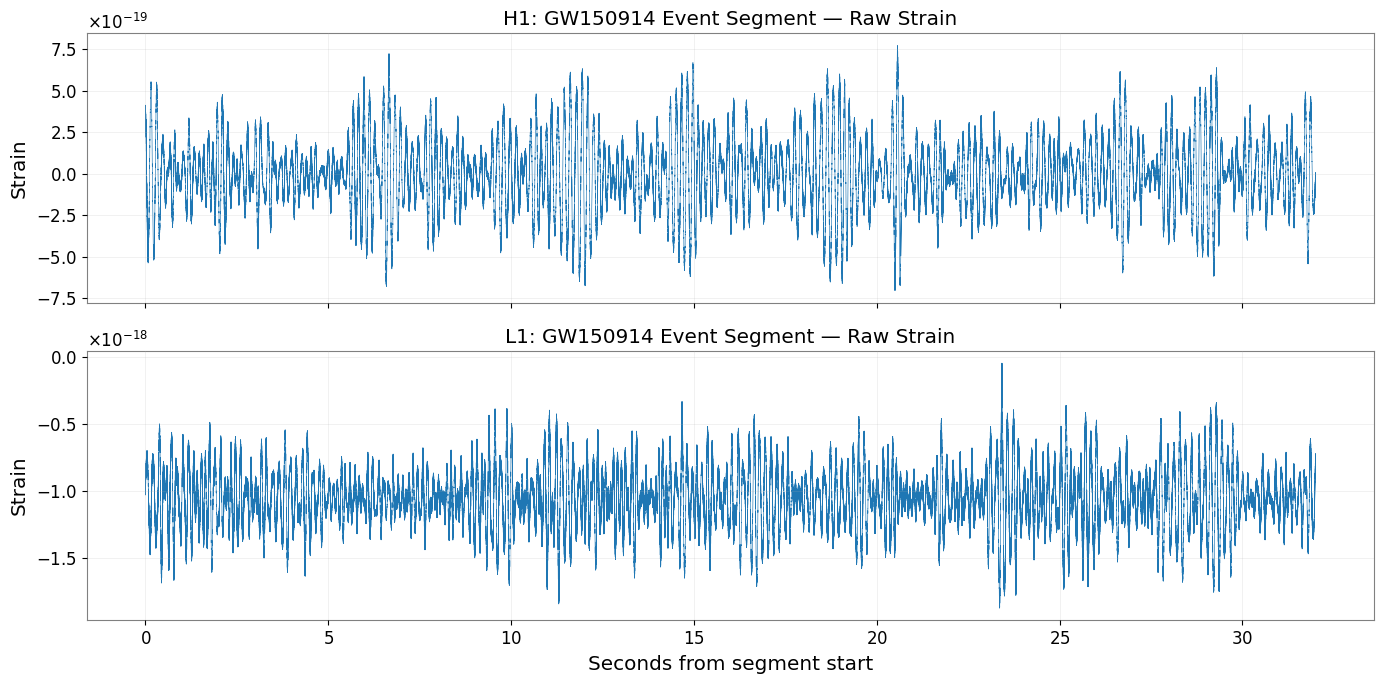

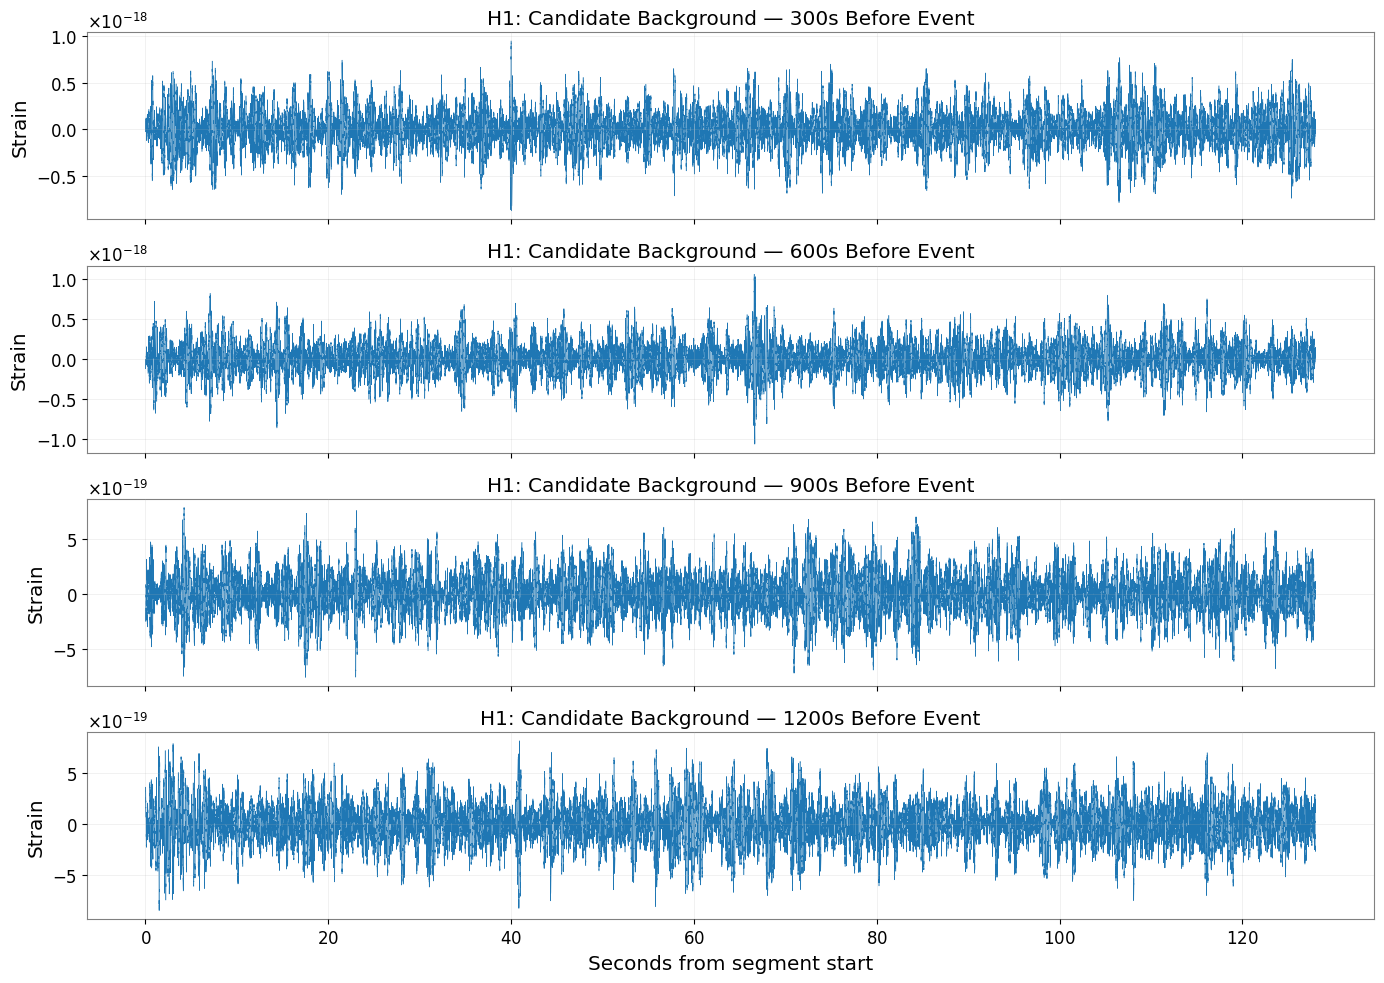

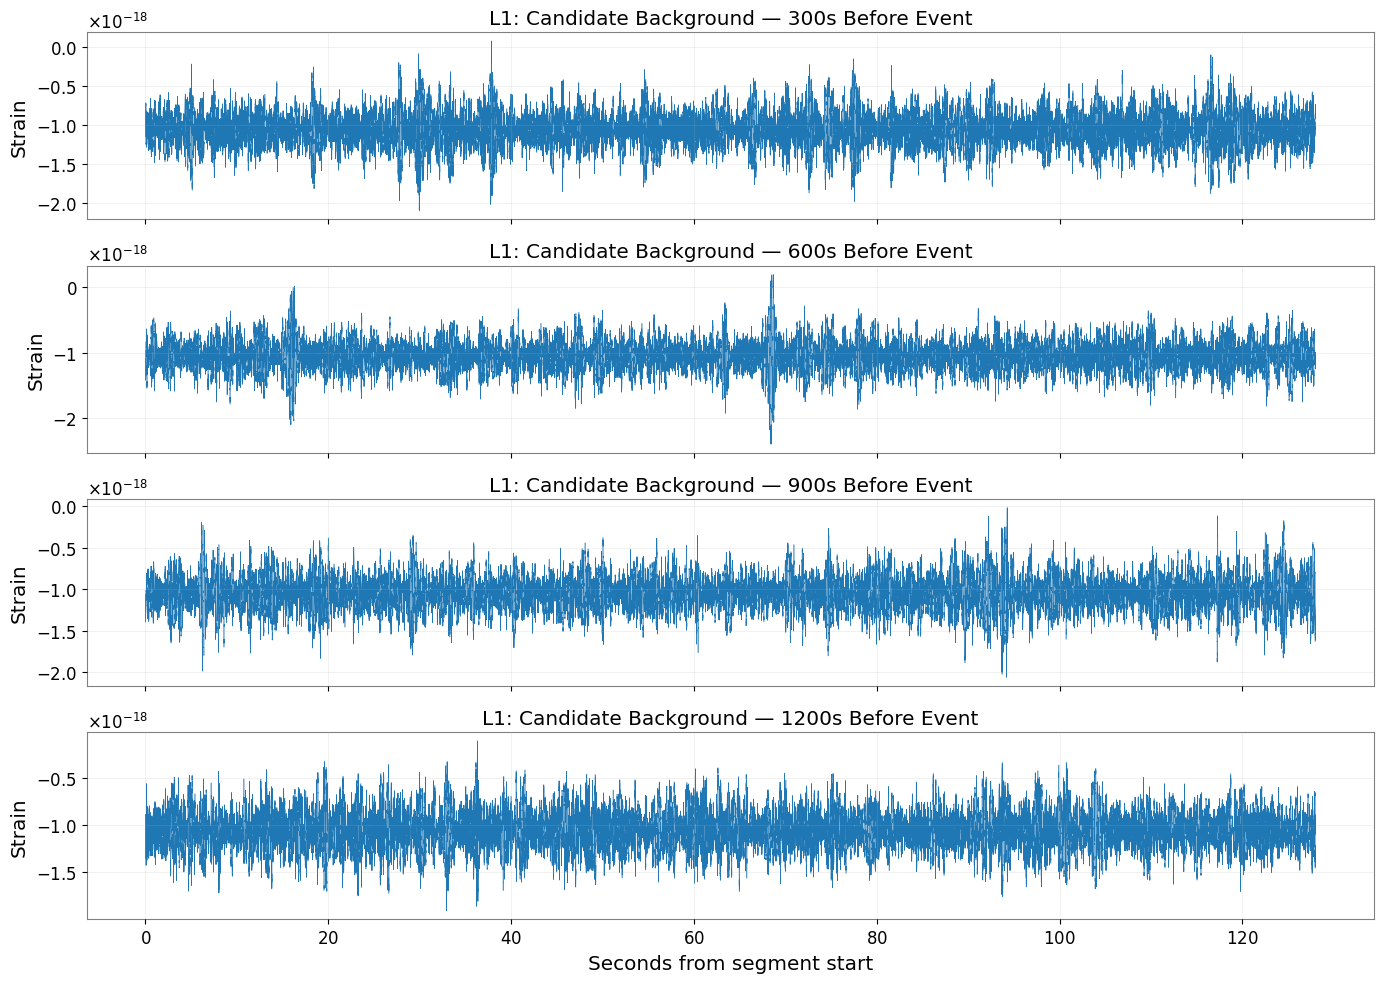

RAW-DATA SUMMARY

H1
event                    std=2.216e-19  99% |strain|=5.845e-19  range=[-7.045e-19, 7.706e-19]
background_offset_300s   std=2.117e-19  99% |strain|=5.761e-19  range=[-8.722e-19, 9.455e-19]
background_offset_600s   std=2.105e-19  99% |strain|=5.716e-19  range=[-1.071e-18, 1.063e-18]
background_offset_900s   std=2.027e-19  99% |strain|=5.306e-19  range=[-7.652e-19, 7.899e-19]
background_offset_1200s  std=2.115e-19  99% |strain|=5.767e-19  range=[-8.476e-19, 8.147e-19]

L1
event                    std=2.328e-19  99% |strain|=1.610e-18  range=[-1.870e-18, -4.600e-20]
background_offset_300s   std=2.250e-19  99% |strain|=1.622e-18  range=[-2.103e-18, 7.717e-20]
background_offset_600s   std=2.328e-19  99% |strain|=1.603e-18  range=[-2.404e-18, 1.998e-19]
background_offset_900s   std=2.167e-19  99% |strain|=1.567e-18  range=[-2.068e-18, -1.181e-20]
background_offset_1200s  std=2.072e-19  99% |strain|=1.533e-18  range=[-1.908e-18, -9.854e-20]

Saved inspection statistics to 

In [4]:

# PHASE 2A — Inspect raw event and background strain
# No filtering, whitening, or normalization is applied here.

import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"

FS = 4096
SEGMENT_DURATION = 128
OFFSETS = [300, 600, 900, 1200]

# Load the saved raw event data.
event = {
    "H1": np.load(RAW_DIR / "H1_GW150914_raw.npy"),
    "L1": np.load(RAW_DIR / "L1_GW150914_raw.npy"),
}

# Load candidate background data.
backgrounds = {}
for detector in ["H1", "L1"]:
    backgrounds[detector] = {}
    for offset in OFFSETS:
        filename = f"{detector}_background_offset_{offset}s.npy"
        backgrounds[detector][offset] = np.load(RAW_DIR / filename)

# Plot event data: 32 seconds.
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

event_t = np.arange(len(event["H1"])) / FS

for ax, detector in zip(axes, ["H1", "L1"]):
    ax.plot(event_t, event[detector], linewidth=0.45)
    ax.set_title(f"{detector}: GW150914 Event Segment — Raw Strain")
    ax.set_ylabel("Strain")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Seconds from segment start")
plt.tight_layout()
plt.show()

# Plot each background segment.
for detector in ["H1", "L1"]:
    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

    for ax, offset in zip(axes, OFFSETS):
        values = backgrounds[detector][offset]
        time_axis = np.arange(len(values)) / FS

        ax.plot(time_axis, values, linewidth=0.35)
        ax.set_title(f"{detector}: Candidate Background — {offset}s Before Event")
        ax.set_ylabel("Strain")
        ax.grid(alpha=0.25)

    axes[-1].set_xlabel("Seconds from segment start")
    plt.tight_layout()
    plt.show()

# Record basic robust and non-robust statistics.
# These help flag segments for closer inspection; they do not certify quality.
report = {}

for detector in ["H1", "L1"]:
    report[detector] = {}

    for label, values in [
        ("event", event[detector]),
        *[
            (f"background_offset_{offset}s", backgrounds[detector][offset])
            for offset in OFFSETS
        ]
    ]:
        median = np.median(values)
        mad = np.median(np.abs(values - median))

        report[detector][label] = {
            "samples": int(len(values)),
            "mean": float(np.mean(values)),
            "standard_deviation": float(np.std(values)),
            "median": float(median),
            "median_absolute_deviation": float(mad),
            "minimum": float(np.min(values)),
            "maximum": float(np.max(values)),
            "percentile_99_abs": float(np.percentile(np.abs(values), 99)),
            "finite_values": bool(np.isfinite(values).all())
        }

print("RAW-DATA SUMMARY")
for detector, entries in report.items():
    print(f"\n{detector}")
    for label, stats in entries.items():
        print(
            f"{label:24s} "
            f"std={stats['standard_deviation']:.3e}  "
            f"99% |strain|={stats['percentile_99_abs']:.3e}  "
            f"range=[{stats['minimum']:.3e}, {stats['maximum']:.3e}]"
        )

with open(REPORT_DIR / "raw_data_inspection.json", "w") as f:
    json.dump(report, f, indent=2)

print("\nSaved inspection statistics to reports/raw_data_inspection.json")
print("Do not discard any segment based on standard deviation alone.")


SAVED L1
  samples: 131072
  min/max: -1.8697138664295834e-18 -4.600351113045829e-20
  mean: -1.0518986985481623e-18
  first 8: [-9.57782180e-19 -9.44008859e-19 -9.68975657e-19 -1.00720009e-18
 -1.02819738e-18 -1.00508109e-18 -9.81986942e-19 -9.68522746e-19]
  last 8: [-7.70999143e-19 -8.01422561e-19 -8.09524093e-19 -7.72193916e-19
 -7.23749311e-19 -7.18181209e-19 -7.29759972e-19 -7.35275811e-19]

FRESH L1 DOWNLOAD
  samples: 131072
  min/max: -1.8697138664295834e-18 -4.600351113045829e-20
  mean: -1.0518986985481623e-18
  first 8: [-9.57782180e-19 -9.44008859e-19 -9.68975657e-19 -1.00720009e-18
 -1.02819738e-18 -1.00508109e-18 -9.81986942e-19 -9.68522746e-19]
  last 8: [-7.70999143e-19 -8.01422561e-19 -8.09524093e-19 -7.72193916e-19
 -7.23749311e-19 -7.18181209e-19 -7.29759972e-19 -7.35275811e-19]

COMPARISON
  max absolute difference: 0.0
  correlation: 0.9999999999999998
  identical: True


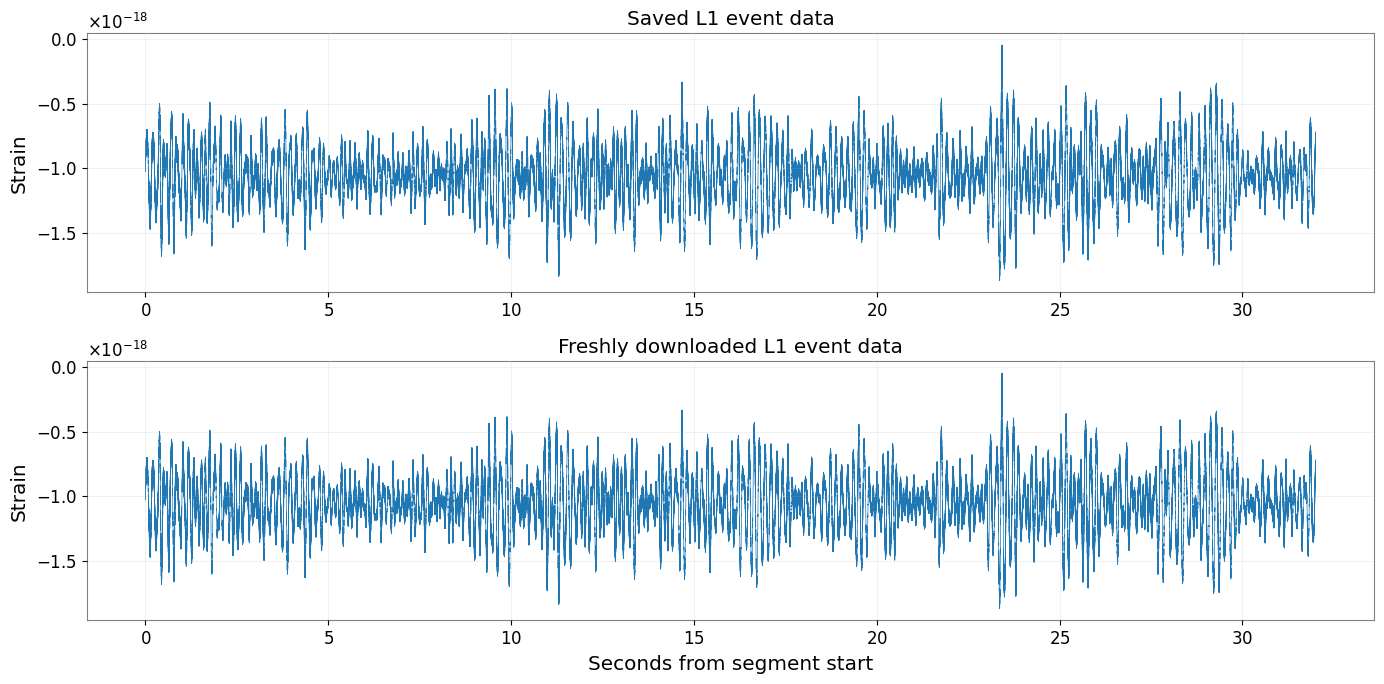

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from gwpy.timeseries import TimeSeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"

FS = 4096
EVENT_GPS = 1126259462.4
START_GPS = EVENT_GPS - 16
END_GPS = EVENT_GPS + 16

# Load saved data and independently fetch the same interval
saved = np.load(RAW_DIR / "L1_GW150914_raw.npy")

fresh_ts = TimeSeries.fetch_open_data(
    "L1",
    START_GPS,
    END_GPS,
    sample_rate=FS,
    cache=True
)
fresh = np.asarray(fresh_ts.value)

print("SAVED L1")
print("  samples:", len(saved))
print("  min/max:", np.min(saved), np.max(saved))
print("  mean:", np.mean(saved))
print("  first 8:", saved[:8])
print("  last 8:", saved[-8:])

print("\nFRESH L1 DOWNLOAD")
print("  samples:", len(fresh))
print("  min/max:", np.min(fresh), np.max(fresh))
print("  mean:", np.mean(fresh))
print("  first 8:", fresh[:8])
print("  last 8:", fresh[-8:])

if len(saved) == len(fresh):
    difference = saved - fresh
    print("\nCOMPARISON")
    print("  max absolute difference:", np.max(np.abs(difference)))
    print("  correlation:", np.corrcoef(saved, fresh)[0, 1])
    print("  identical:", np.array_equal(saved, fresh))
else:
    print("\nSample counts differ; compare timing before comparing values.")

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(np.arange(len(saved)) / FS, saved, linewidth=0.5)
axes[0].set_title("Saved L1 event data")
axes[0].set_ylabel("Strain")
axes[0].grid(alpha=0.25)

axes[1].plot(np.arange(len(fresh)) / FS, fresh, linewidth=0.5)
axes[1].set_title("Freshly downloaded L1 event data")
axes[1].set_xlabel("Seconds from segment start")
axes[1].set_ylabel("Strain")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


H1
Raw mean:          -3.735450e-22
Subtracted mean:   -9.403955e-38
Raw standard dev:  2.215893e-19
After subtraction: 2.215893e-19

L1
Raw mean:          -1.051899e-18
Subtracted mean:   -7.271608e-35
Raw standard dev:  2.327736e-19
After subtraction: 2.327736e-19


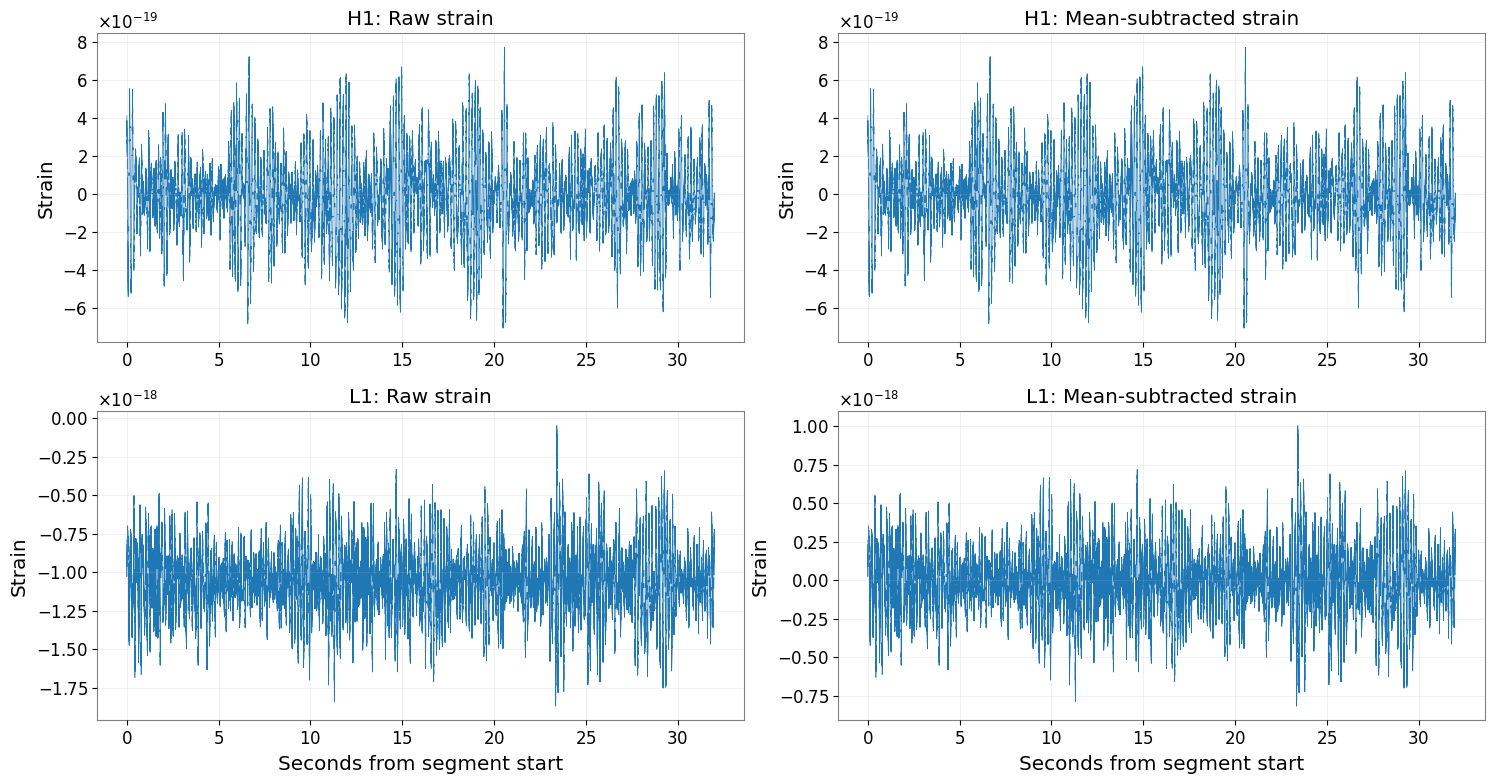

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RAW_DIR = Path("/content/gw150914_flagship/raw")
FS = 4096

event = {
    "H1": np.load(RAW_DIR / "H1_GW150914_raw.npy"),
    "L1": np.load(RAW_DIR / "L1_GW150914_raw.npy"),
}

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

for row, detector in enumerate(["H1", "L1"]):
    raw = event[detector]
    demeaned = raw - np.mean(raw)
    time = np.arange(len(raw)) / FS

    axes[row, 0].plot(time, raw, linewidth=0.45)
    axes[row, 0].set_title(f"{detector}: Raw strain")
    axes[row, 0].set_ylabel("Strain")
    axes[row, 0].grid(alpha=0.25)

    axes[row, 1].plot(time, demeaned, linewidth=0.45)
    axes[row, 1].set_title(f"{detector}: Mean-subtracted strain")
    axes[row, 1].set_ylabel("Strain")
    axes[row, 1].grid(alpha=0.25)

    print(f"\n{detector}")
    print(f"Raw mean:          {np.mean(raw):.6e}")
    print(f"Subtracted mean:   {np.mean(demeaned):.6e}")
    print(f"Raw standard dev:  {np.std(raw):.6e}")
    print(f"After subtraction: {np.std(demeaned):.6e}")

axes[1, 0].set_xlabel("Seconds from segment start")
axes[1, 1].set_xlabel("Seconds from segment start")

plt.tight_layout()
plt.show()

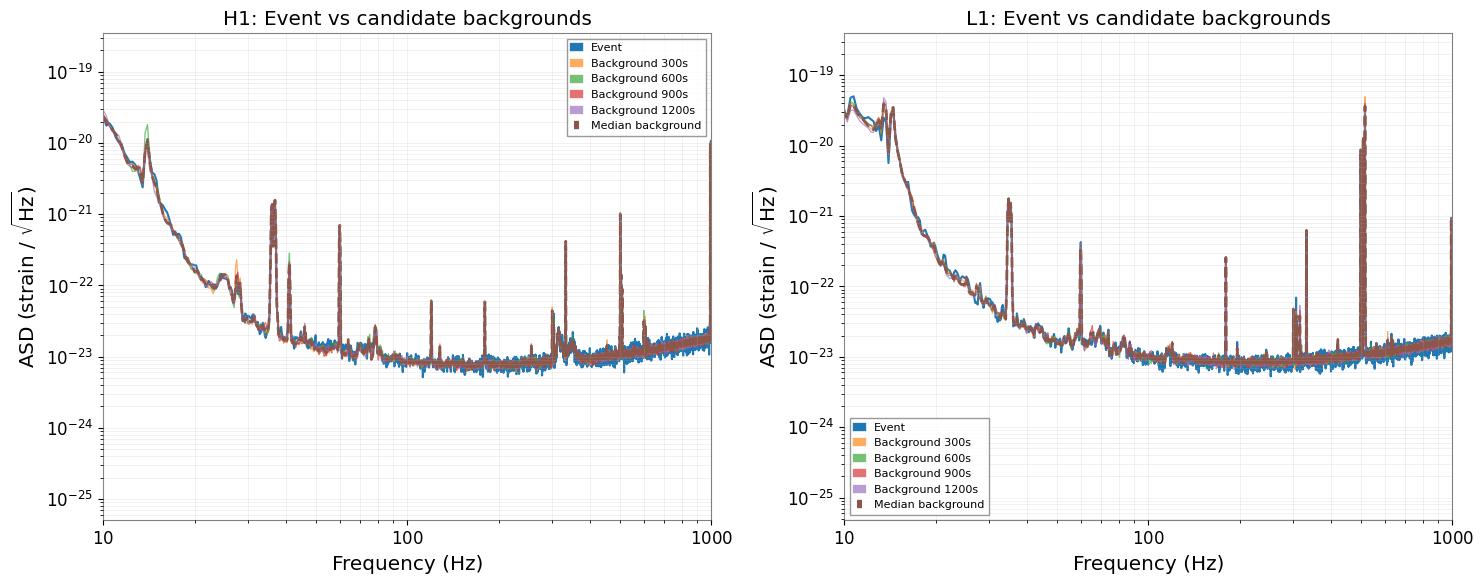

ASD ANALYSIS — INTEGRATED 20–300 Hz NOISE

H1
event               : 1.4832e-21 strain
background_300s     : 1.4783e-21 strain
background_600s     : 1.4857e-21 strain
background_900s     : 1.4858e-21 strain
background_1200s    : 1.4820e-21 strain

L1
event               : 1.5913e-21 strain
background_300s     : 1.5650e-21 strain
background_600s     : 1.5684e-21 strain
background_900s     : 1.5673e-21 strain
background_1200s    : 1.5673e-21 strain

Saved plot: /content/gw150914_flagship/figures/phase3A_asd_comparison.png
Saved spectrum report: /content/gw150914_flagship/reports/asd_comparison.json


In [7]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import welch

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
PROCESSED_DIR = PROJECT_DIR / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"
REPORT_DIR = PROJECT_DIR / "reports"

for folder in [PROCESSED_DIR, FIGURES_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FS = 4096
OFFSETS = [300, 600, 900, 1200]

# Four-second Welch windows with 50% overlap
NPERSEG = 4 * FS
NOVERLAP = NPERSEG // 2

data = {}
for detector in ["H1", "L1"]:
    data[detector] = {
        "event": np.load(RAW_DIR / f"{detector}_GW150914_raw.npy")
    }
    for offset in OFFSETS:
        label = f"background_{offset}s"
        filename = f"{detector}_background_offset_{offset}s.npy"
        data[detector][label] = np.load(RAW_DIR / filename)

results = {}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, detector in zip(axes, ["H1", "L1"]):
    results[detector] = {}
    background_asds = []

    for label, strain in data[detector].items():
        if not np.isfinite(strain).all():
            raise ValueError(f"{detector} {label} contains non-finite values.")

        frequencies, psd = welch(
            strain,
            fs=FS,
            window="hann",
            nperseg=NPERSEG,
            noverlap=NOVERLAP,
            detrend="constant",
            scaling="density"
        )

        asd = np.sqrt(np.maximum(psd, 0))
        results[detector][label] = {
            "frequencies_hz": frequencies.tolist(),
            "asd_strain_per_sqrt_hz": asd.tolist()
        }

        if label == "event":
            ax.loglog(frequencies[1:], asd[1:],
                      label="Event", linewidth=1.5)
        else:
            background_asds.append(asd)
            ax.loglog(frequencies[1:], asd[1:],
                      alpha=0.65, linewidth=0.9,
                      label=label.replace("background_", "Background "))

    # Add the median of the four candidate-background ASD curves.
    median_background_asd = np.median(np.vstack(background_asds), axis=0)
    ax.loglog(
        frequencies[1:],
        median_background_asd[1:],
        linestyle="--",
        linewidth=2,
        label="Median background"
    )

    ax.set_xlim(10, 1000)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel(r"ASD (strain / $\sqrt{\mathrm{Hz}}$)")
    ax.set_title(f"{detector}: Event vs candidate backgrounds")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
figure_path = FIGURES_DIR / "phase3A_asd_comparison.png"
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

# Save numerical results for reproducibility.
output_path = REPORT_DIR / "asd_comparison.json"
with open(output_path, "w") as f:
    json.dump(results, f)

# Compare integrated noise over 20–300 Hz.
print("ASD ANALYSIS — INTEGRATED 20–300 Hz NOISE")
for detector in ["H1", "L1"]:
    print(f"\n{detector}")
    for label, strain in data[detector].items():
        f, psd = welch(
            strain,
            fs=FS,
            window="hann",
            nperseg=NPERSEG,
            noverlap=NOVERLAP,
            detrend="constant",
            scaling="density"
        )
        band = (f >= 20) & (f <= 300)
        band_rms = np.sqrt(np.trapezoid(psd[band], f[band]))
        print(f"{label:20s}: {band_rms:.4e} strain")

print(f"\nSaved plot: {figure_path}")
print(f"Saved spectrum report: {output_path}")

In [8]:
import json
import math
from pathlib import Path
from gwosc.timeline import get_segments

PROJECT_DIR = Path("/content/gw150914_flagship")
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

EVENT_GPS = 1126259462.4
OFFSETS = [300, 600, 900, 1200]

# Intervals correspond to the data already downloaded.
intervals = {
    "GW150914_event": (
        EVENT_GPS - 16,
        EVENT_GPS + 16
    )
}

for offset in OFFSETS:
    center = EVENT_GPS - offset
    intervals[f"background_offset_{offset}s"] = (
        center - 64,
        center + 64
    )

def fully_covered(start, end, segments):
    """Check whether the union of official segments covers [start, end)."""
    cursor = start

    for seg_start, seg_end in sorted(segments):
        if seg_end <= cursor:
            continue
        if seg_start > cursor:
            return False
        cursor = max(cursor, seg_end)
        if cursor >= end:
            return True

    return cursor >= end

report = {}

for detector in ["H1", "L1"]:
    print(f"\n{detector}: querying official DATA segments")

    query_start = math.floor(min(s for s, e in intervals.values()))
    query_end = math.ceil(max(e for s, e in intervals.values()))

    try:
        segments = get_segments(
            f"{detector}_DATA",
            query_start,
            query_end
        )

        detector_results = {}

        for name, (start, end) in intervals.items():
            # DQ segments are represented at whole-second resolution.
            check_start = math.floor(start)
            check_end = math.ceil(end)

            covered = fully_covered(
                check_start,
                check_end,
                segments
            )

            detector_results[name] = {
                "start_gps": start,
                "end_gps": end,
                "integer_second_interval_fully_covered": covered
            }

            print(
                f"{name:24s} "
                f"GPS [{start:.1f}, {end:.1f}) "
                f"fully covered: {covered}"
            )

        report[detector] = detector_results

    except Exception as exc:
        print(
            f"Could not retrieve or interpret {detector} DATA flags: "
            f"{type(exc).__name__}: {exc}"
        )
        report[detector] = {
            "query_error": f"{type(exc).__name__}: {exc}"
        }

output_path = REPORT_DIR / "official_data_flag_check.json"

with open(output_path, "w") as f:
    json.dump(report, f, indent=2)

print(f"\nSaved report: {output_path}")


H1: querying official DATA segments
GW150914_event           GPS [1126259446.4, 1126259478.4) fully covered: True
background_offset_300s   GPS [1126259098.4, 1126259226.4) fully covered: True
background_offset_600s   GPS [1126258798.4, 1126258926.4) fully covered: True
background_offset_900s   GPS [1126258498.4, 1126258626.4) fully covered: True
background_offset_1200s  GPS [1126258198.4, 1126258326.4) fully covered: True

L1: querying official DATA segments
GW150914_event           GPS [1126259446.4, 1126259478.4) fully covered: True
background_offset_300s   GPS [1126259098.4, 1126259226.4) fully covered: True
background_offset_600s   GPS [1126258798.4, 1126258926.4) fully covered: True
background_offset_900s   GPS [1126258498.4, 1126258626.4) fully covered: True
background_offset_1200s  GPS [1126258198.4, 1126258326.4) fully covered: True

Saved report: /content/gw150914_flagship/reports/official_data_flag_check.json


## Apply a controlled bandpass filter


H1
  Raw standard deviation:      2.215893e-19
  Filtered standard deviation: 1.717305e-21
  Filtered minimum:            -5.625682e-20
  Filtered maximum:            1.598197e-20

L1
  Raw standard deviation:      2.327736e-19
  Filtered standard deviation: 1.391127e-20
  Filtered minimum:            -6.088566e-20
  Filtered maximum:            4.858262e-20


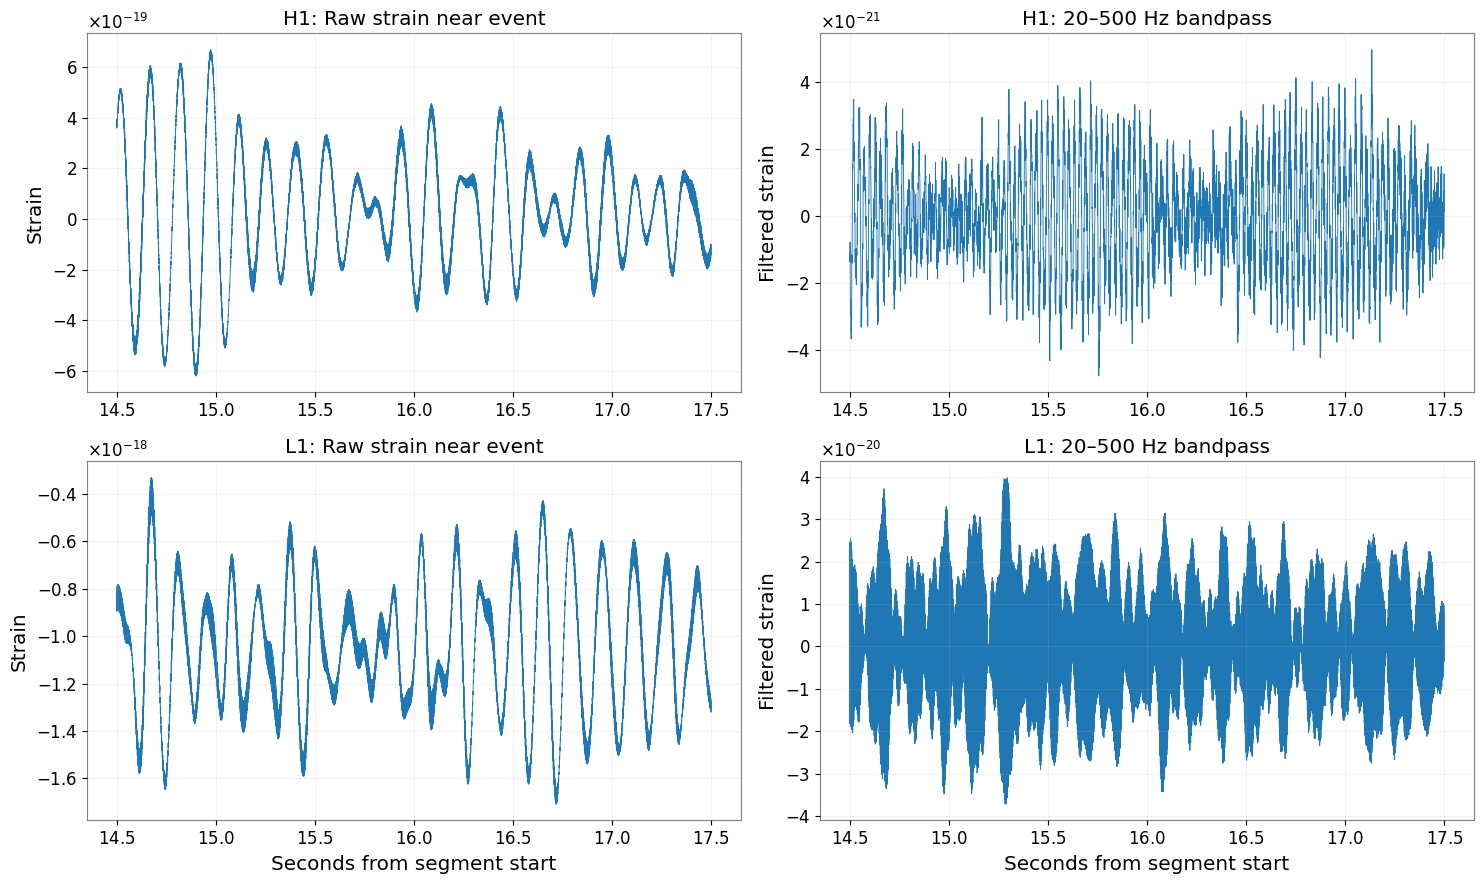

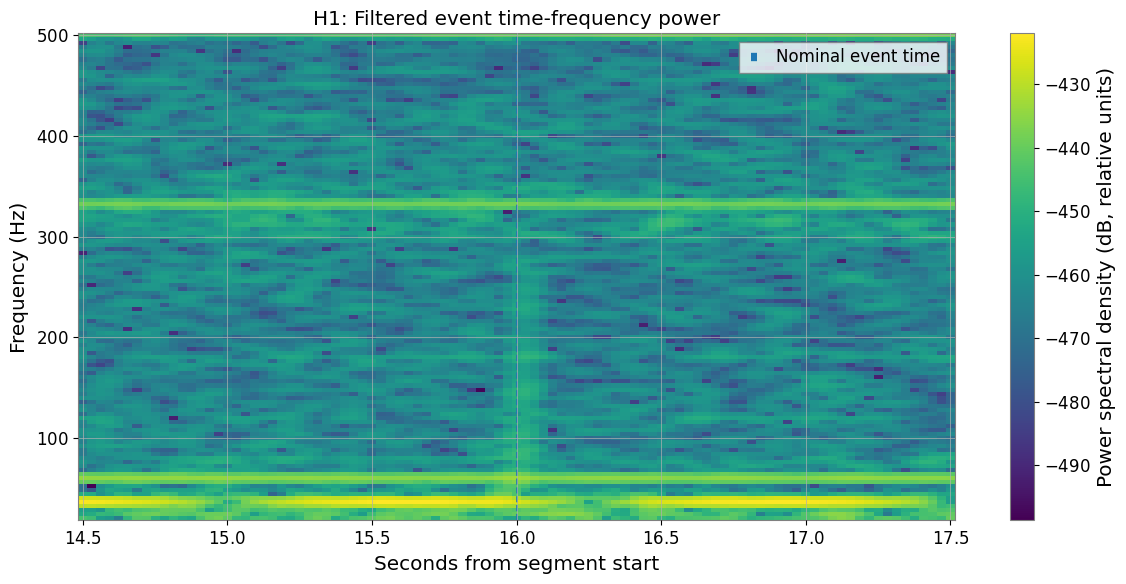


Saved filtered arrays to: /content/gw150914_flagship/processed
Saved figures to: /content/gw150914_flagship/figures


In [9]:
import json
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import butter, sosfiltfilt, spectrogram

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
PROCESSED_DIR = PROJECT_DIR / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"
REPORT_DIR = PROJECT_DIR / "reports"

for folder in [PROCESSED_DIR, FIGURES_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FS = 4096
EVENT_GPS = 1126259462.4
EVENT_TIME_IN_SEGMENT = 16.0
LOW_HZ = 20.0
HIGH_HZ = 500.0
FILTER_ORDER = 4

# Design a numerically stable Butterworth bandpass.
sos = butter(
    FILTER_ORDER,
    [LOW_HZ, HIGH_HZ],
    btype="bandpass",
    fs=FS,
    output="sos"
)

raw_event = {}
filtered_event = {}

for detector in ["H1", "L1"]:
    raw = np.load(RAW_DIR / f"{detector}_GW150914_raw.npy")

    if not np.isfinite(raw).all():
        raise ValueError(f"{detector} event data contains non-finite values.")

    # Remove the constant mean for processing, without altering raw files.
    centered = raw - np.mean(raw)

    # Forward-backward filtering avoids a net phase shift.
    filtered = sosfiltfilt(sos, centered)

    raw_event[detector] = raw
    filtered_event[detector] = filtered

    np.save(
        PROCESSED_DIR / f"{detector}_GW150914_bandpass_20_500Hz.npy",
        filtered
    )

    print(f"\n{detector}")
    print(f"  Raw standard deviation:      {np.std(raw):.6e}")
    print(f"  Filtered standard deviation: {np.std(filtered):.6e}")
    print(f"  Filtered minimum:            {np.min(filtered):.6e}")
    print(f"  Filtered maximum:            {np.max(filtered):.6e}")

# Plot the event-centered region; avoid interpreting filter-edge regions.
time = np.arange(len(raw_event["H1"])) / FS
zoom = (time >= EVENT_TIME_IN_SEGMENT - 1.5) & (
    time <= EVENT_TIME_IN_SEGMENT + 1.5
)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for row, detector in enumerate(["H1", "L1"]):
    axes[row, 0].plot(
        time[zoom], raw_event[detector][zoom], linewidth=0.65
    )
    axes[row, 0].set_title(f"{detector}: Raw strain near event")
    axes[row, 0].set_ylabel("Strain")
    axes[row, 0].grid(alpha=0.25)

    axes[row, 1].plot(
        time[zoom], filtered_event[detector][zoom], linewidth=0.65
    )
    axes[row, 1].set_title(f"{detector}: 20–500 Hz bandpass")
    axes[row, 1].set_ylabel("Filtered strain")
    axes[row, 1].grid(alpha=0.25)

axes[1, 0].set_xlabel("Seconds from segment start")
axes[1, 1].set_xlabel("Seconds from segment start")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "phase4A_raw_vs_bandpass.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# Inspect time-frequency structure in the filtered H1 event data.
frequencies, times, power = spectrogram(
    filtered_event["H1"],
    fs=FS,
    window="hann",
    nperseg=1024,
    noverlap=896,
    detrend="constant",
    scaling="density",
    mode="psd"
)

time_mask = (
    (times >= EVENT_TIME_IN_SEGMENT - 1.5)
    & (times <= EVENT_TIME_IN_SEGMENT + 1.5)
)
freq_mask = (frequencies >= 20) & (frequencies <= 500)

fig, ax = plt.subplots(figsize=(12, 6))
mesh = ax.pcolormesh(
    times[time_mask],
    frequencies[freq_mask],
    10 * np.log10(power[np.ix_(freq_mask, time_mask)] + 1e-60),
    shading="auto"
)
ax.axvline(
    EVENT_TIME_IN_SEGMENT,
    linestyle="--",
    linewidth=1.2,
    label="Nominal event time"
)
ax.set_xlabel("Seconds from segment start")
ax.set_ylabel("Frequency (Hz)")
ax.set_title("H1: Filtered event time-frequency power")
ax.legend()
fig.colorbar(mesh, ax=ax, label="Power spectral density (dB, relative units)")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "phase4A_H1_spectrogram.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

print("\nSaved filtered arrays to:", PROCESSED_DIR)
print("Saved figures to:", FIGURES_DIR)

Brighter colors: higher estimated power.



Darker colors: lower estimated power.



Horizontal lines: persistent frequencies or narrowband features.

## a clearer gravitational-wave spectrogram

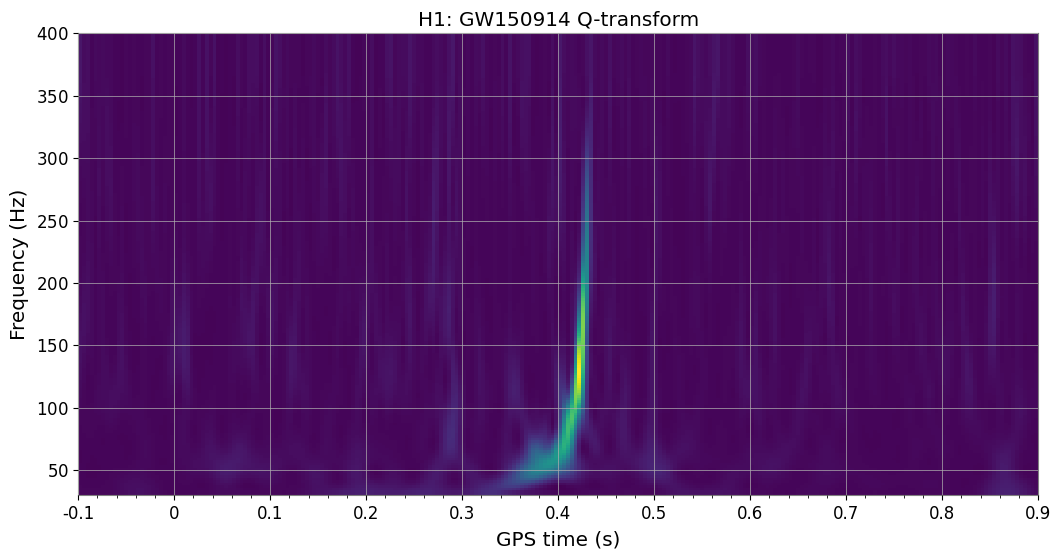

Saved: /content/gw150914_flagship/figures/phase4B_H1_qtransform.png


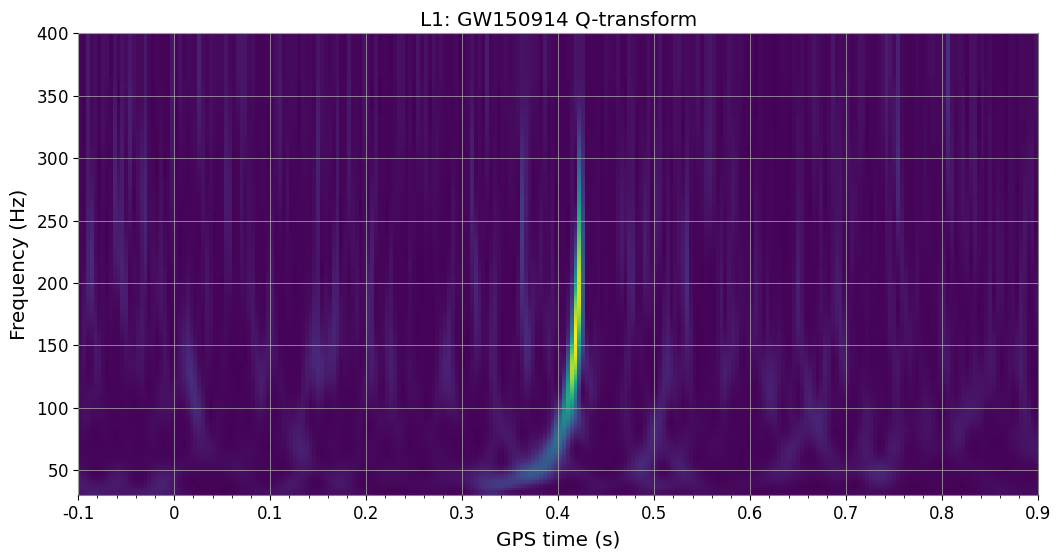

Saved: /content/gw150914_flagship/figures/phase4B_L1_qtransform.png
Q-transform step finished.


In [10]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from gwpy.timeseries import TimeSeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
FIGURES_DIR = PROJECT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FS = 4096
EVENT_GPS = 1126259462.4

for detector in ["H1", "L1"]:
    raw = np.load(RAW_DIR / f"{detector}_GW150914_raw.npy")

    strain = TimeSeries(
        raw,
        t0=EVENT_GPS - 16,
        dt=1 / FS,
        channel=f"{detector}:GWOSC-STRAIN"
    )

    # Give the Q-transform more data around the event.
    centered = strain.crop(
        EVENT_GPS - 2,
        EVENT_GPS + 2
    )

    # Transform the longer segment, then display the event-centered region.
    qspec = centered.q_transform(
        frange=(30, 400),
        qrange=(4, 32),
        tres=0.004,
        fres=2
    )

    fig = qspec.plot()
    ax = fig.gca()
    ax.set_xlim(EVENT_GPS - 0.5, EVENT_GPS + 0.5)
    ax.set_ylim(30, 400)
    ax.set_title(f"{detector}: GW150914 Q-transform")
    ax.set_xlabel("GPS time (s)")
    ax.set_ylabel("Frequency (Hz)")

    output = FIGURES_DIR / f"phase4B_{detector}_qtransform.png"
    fig.savefig(output, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", output)

print("Q-transform step finished.")


## check the event-centered timing

In [11]:
import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
EVENT_GPS = 1126259462.4

for detector in ["H1", "L1"]:
    path = PROJECT_DIR / "processed" / f"{detector}_GW150914_bandpass_20_500Hz.npy"
    data = np.load(path)

    t = np.arange(len(data)) / 4096 - 16
    event_window = (t >= -0.5) & (t <= 0.5)

    local_t = t[event_window]
    local_data = data[event_window]

    peak_idx = np.argmax(np.abs(local_data))

    print(f"\n{detector}")
    print(f"Largest absolute filtered peak: {local_t[peak_idx]:+.4f} s relative to event")
    print(f"GPS time: {EVENT_GPS + local_t[peak_idx]:.4f}")
    print(f"Peak amplitude: {local_data[peak_idx]:.4e}")


H1
Largest absolute filtered peak: -0.2437 s relative to event
GPS time: 1126259462.1563
Peak amplitude: -4.7909e-21

L1
Largest absolute filtered peak: +0.0806 s relative to event
GPS time: 1126259462.4806
Peak amplitude: -3.4196e-20


## inspect the waveform around the merger

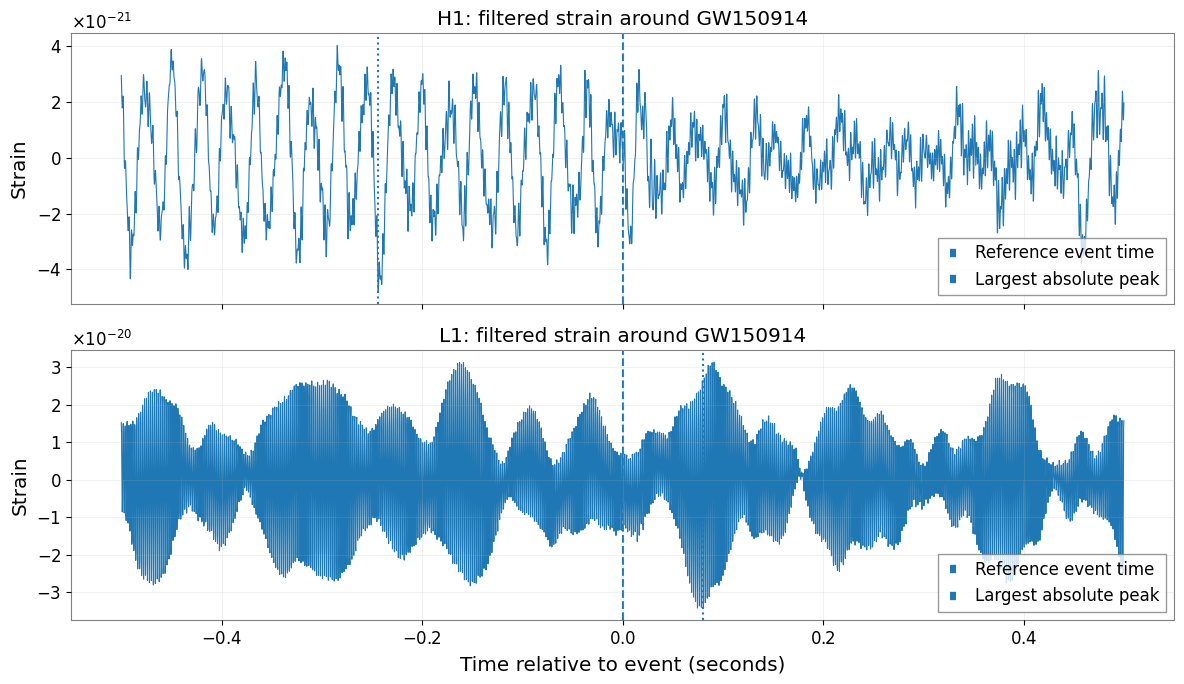

Saved: /content/gw150914_flagship/figures/phase4C_event_waveforms.png


In [12]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
FIGURES_DIR = PROJECT_DIR / "figures"

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, detector in zip(axes, ["H1", "L1"]):
    path = (
        PROJECT_DIR / "processed" /
        f"{detector}_GW150914_bandpass_20_500Hz.npy"
    )
    data = np.load(path)

    t = np.arange(len(data)) / 4096 - 16
    mask = (t >= -0.5) & (t <= 0.5)

    ax.plot(t[mask], data[mask], linewidth=0.8)
    ax.axvline(0, linestyle="--", label="Reference event time")
    ax.axvline(-0.2437 if detector == "H1" else 0.0806,
               linestyle=":", label="Largest absolute peak")
    ax.set_title(f"{detector}: filtered strain around GW150914")
    ax.set_ylabel("Strain")
    ax.grid(True, alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Time relative to event (seconds)")
plt.tight_layout()

output = FIGURES_DIR / "phase4C_event_waveforms.png"
plt.savefig(output, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", output)


## Whiten H1 and L1


Processing H1...
Saved: /content/gw150914_flagship/processed/H1_GW150914_whitened.npy
Samples: 98304
Duration (s): 24.0
Whitened mean: -6.716909794689817e-05
Whitened standard deviation: 0.997765497982158


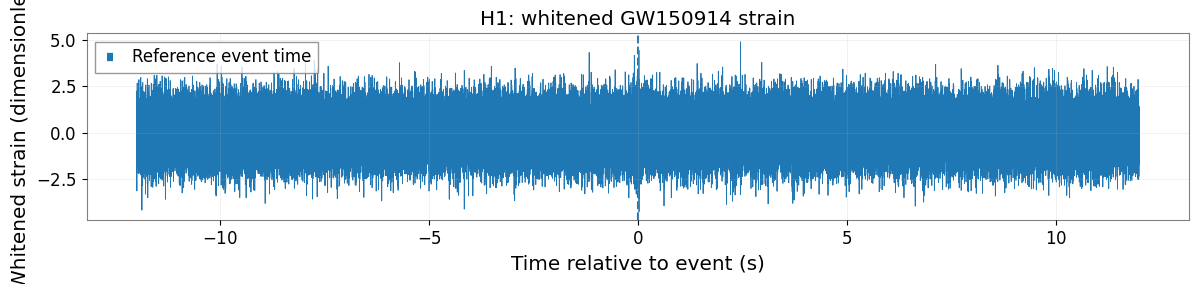


Processing L1...
Saved: /content/gw150914_flagship/processed/L1_GW150914_whitened.npy
Samples: 98304
Duration (s): 24.0
Whitened mean: 2.013509048540608e-05
Whitened standard deviation: 0.9846363064719202


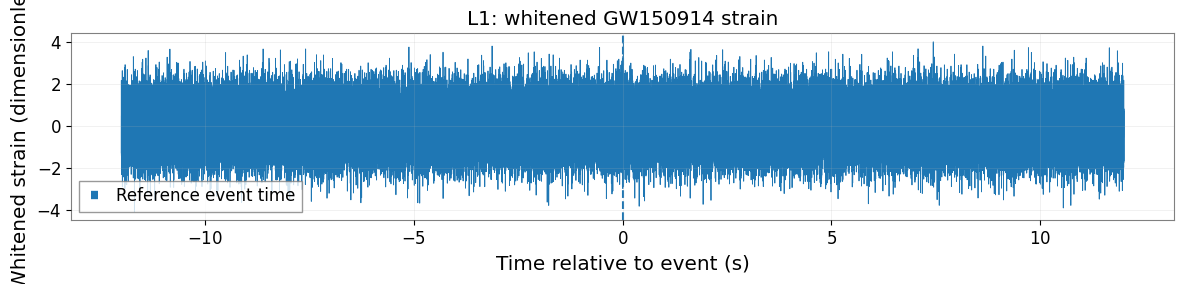


Phase 5A complete.


In [13]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from gwpy.timeseries import TimeSeries
from gwpy.frequencyseries import FrequencySeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
PROCESSED_DIR = PROJECT_DIR / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FS = 4096
EVENT_GPS = 1126259462.4
OFFSETS = [300, 600, 900, 1200]

whitened = {}

for detector in ["H1", "L1"]:
    print(f"\nProcessing {detector}...")

    # Load the original event data.
    event_raw = np.load(
        RAW_DIR / f"{detector}_GW150914_raw.npy"
    )

    event_ts = TimeSeries(
        event_raw,
        t0=EVENT_GPS - 16,
        dt=1 / FS
    )

    # Estimate the noise ASD independently from off-source segments.
    asd_estimates = []

    for offset in OFFSETS:
        bg_path = (
            RAW_DIR /
            f"{detector}_background_offset_{offset}s.npy"
        )
        bg = np.load(bg_path)

        bg_ts = TimeSeries(bg, t0=0, dt=1 / FS)

        asd = bg_ts.asd(
            fftlength=4,
            overlap=2,
            method="median"
        )
        asd_estimates.append(asd)

    # Median across the four candidate background ASDs.
    median_asd_values = np.median(
        np.stack([np.asarray(a.value) for a in asd_estimates]),
        axis=0
    )

    median_asd = FrequencySeries(
        median_asd_values,
        f0=asd_estimates[0].f0,
        df=asd_estimates[0].df,
        unit=asd_estimates[0].unit
    )

    # Whiten using the background-derived ASD.
    white_ts = event_ts.whiten(
        asd=median_asd,
        fduration=4,
        highpass=20
    )

    # Save only the central 24 seconds to reduce filter-edge effects.
    central = white_ts.crop(
        EVENT_GPS - 12,
        EVENT_GPS + 12
    )

    white_data = np.asarray(central.value)
    out_path = (
        PROCESSED_DIR /
        f"{detector}_GW150914_whitened.npy"
    )
    np.save(out_path, white_data)
    whitened[detector] = white_data

    print("Saved:", out_path)
    print("Samples:", len(white_data))
    print("Duration (s):", len(white_data) / FS)
    print("Whitened mean:", float(np.mean(white_data)))
    print("Whitened standard deviation:", float(np.std(white_data)))

    # Plot the whitened central event interval.
    t = np.asarray(central.times.value) - EVENT_GPS

    plt.figure(figsize=(12, 3))
    plt.plot(t, white_data, linewidth=0.6)
    plt.axvline(0, linestyle="--", label="Reference event time")
    plt.title(f"{detector}: whitened GW150914 strain")
    plt.xlabel("Time relative to event (s)")
    plt.ylabel("Whitened strain (dimensionless)")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    fig_path = FIGURES_DIR / f"phase5A_{detector}_whitened.png"
    plt.savefig(fig_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

print("\nPhase 5A complete.")


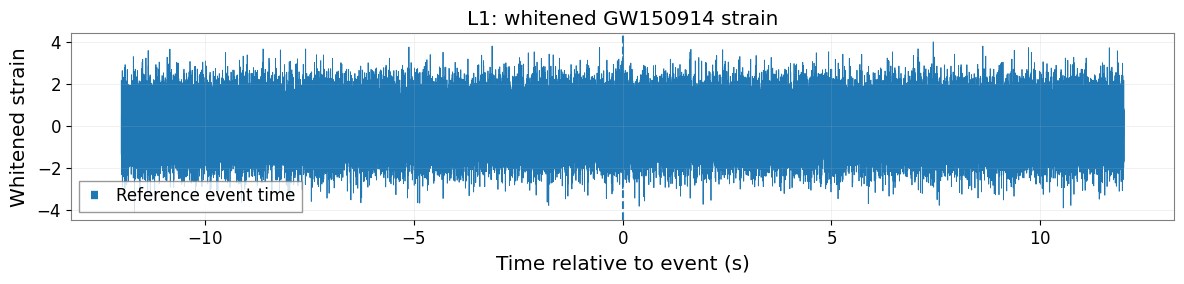

Saved: /content/gw150914_flagship/processed/L1_GW150914_whitened.npy
H1: samples=98304, duration=24.00s, mean=-6.71691e-05, std=0.997765, finite=True
L1: samples=98304, duration=24.00s, mean=2.01351e-05, std=0.984636, finite=True


In [45]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from gwpy.timeseries import TimeSeries
from gwpy.frequencyseries import FrequencySeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
PROCESSED_DIR = PROJECT_DIR / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"

FS = 4096
EVENT_GPS = 1126259462.4
OFFSETS = [300, 600, 900, 1200]

# Process L1; H1 is already saved.
detector = "L1"
raw = np.load(RAW_DIR / f"{detector}_GW150914_raw.npy")
event_ts = TimeSeries(raw, t0=EVENT_GPS - 16, dt=1 / FS)

asd_estimates = []
for offset in OFFSETS:
    bg = np.load(
        RAW_DIR / f"{detector}_background_offset_{offset}s.npy"
    )
    bg_ts = TimeSeries(bg, t0=0, dt=1 / FS)
    asd_estimates.append(
        bg_ts.asd(fftlength=4, overlap=2, method="median")
    )

median_values = np.median(
    np.stack([np.asarray(a.value) for a in asd_estimates]),
    axis=0
)
median_asd = FrequencySeries(
    median_values,
    f0=asd_estimates[0].f0,
    df=asd_estimates[0].df,
    unit=asd_estimates[0].unit
)

white_ts = event_ts.whiten(
    asd=median_asd,
    fduration=4,
    highpass=20
)
central = white_ts.crop(EVENT_GPS - 12, EVENT_GPS + 12)
white_data = np.asarray(central.value)

out_path = PROCESSED_DIR / "L1_GW150914_whitened.npy"
np.save(out_path, white_data)

t = np.asarray(central.times.value) - EVENT_GPS
plt.figure(figsize=(12, 3))
plt.plot(t, white_data, linewidth=0.6)
plt.axvline(0, linestyle="--", label="Reference event time")
plt.title("L1: whitened GW150914 strain")
plt.xlabel("Time relative to event (s)")
plt.ylabel("Whitened strain")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "phase5A_L1_whitened.png",
            dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", out_path)

# Verify both detector arrays.
for det in ["H1", "L1"]:
    p = PROCESSED_DIR / f"{det}_GW150914_whitened.npy"
    x = np.load(p)
    print(
        f"{det}: samples={len(x)}, duration={len(x)/FS:.2f}s, "
        f"mean={np.mean(x):.6g}, std={np.std(x):.6g}, "
        f"finite={np.isfinite(x).all()}"
    )





Matched filtering: H1


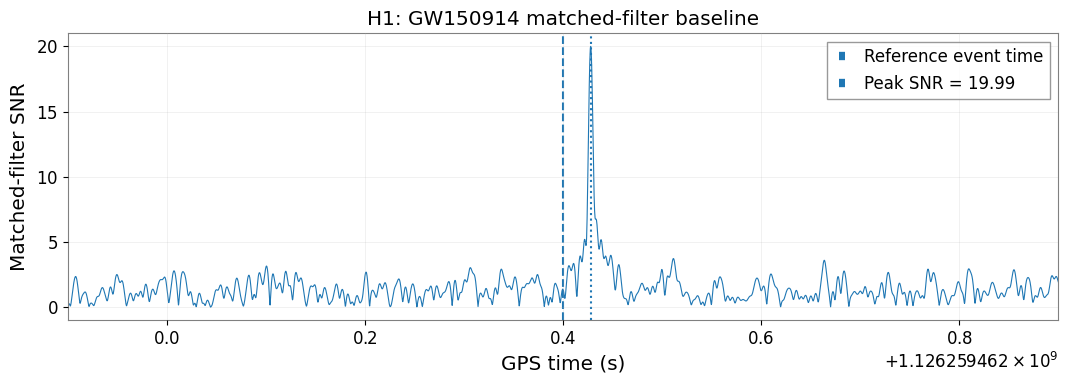

Peak SNR: 19.995
Peak GPS time: 1126259462.428076
Time relative to reference: +0.028076 s
Figure saved: /content/gw150914_flagship/figures/phase6A_H1_matched_filter.png

Matched filtering: L1


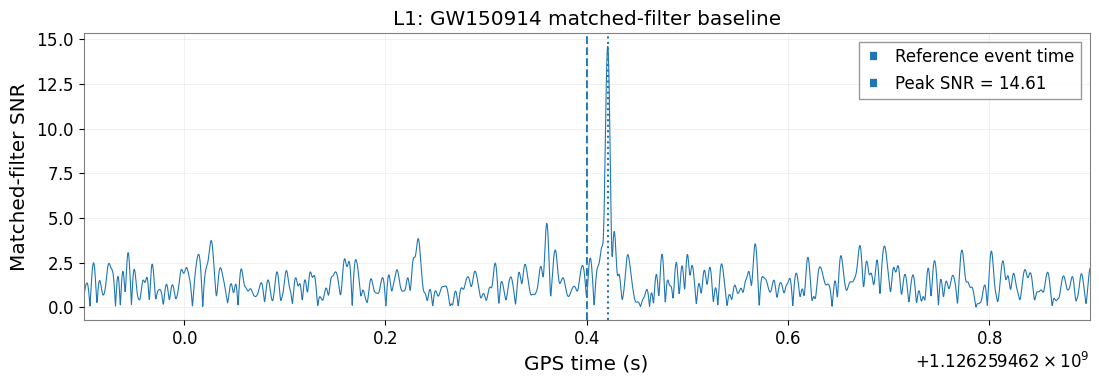

Peak SNR: 14.610
Peak GPS time: 1126259462.420996
Time relative to reference: +0.020996 s
Figure saved: /content/gw150914_flagship/figures/phase6A_L1_matched_filter.png

PHASE 6A COMPLETE
Results saved: /content/gw150914_flagship/reports/matched_filter_baseline.json


In [46]:

# ============================================================
# PHASE 6A — MATCHED-FILTER BASELINE FOR GW150914
# Estimate noise PSD from off-source data and search H1/L1.
# ============================================================

import json
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from pycbc.types import TimeSeries, FrequencySeries
from pycbc.filter import highpass_fir, matched_filter
from pycbc.psd import welch, interpolate
from pycbc.waveform import get_fd_waveform

PROJECT = Path("/content/gw150914_flagship")
RAW = PROJECT / "raw"
REPORTS = PROJECT / "reports"
FIGURES = PROJECT / "figures"

FS = 4096
EVENT_GPS = 1126259462.4
START_GPS = EVENT_GPS - 16
OFFSETS = [300, 600, 900, 1200]

FLOW = 20.0
FHIGH = 500.0

# Use a 32-second event segment.
N = 32 * FS
DELTA_F = 1.0 / 32

# Initial GW150914-like binary black-hole template.
MASS1 = 40.0
MASS2 = 32.0
APPROXIMANT = "IMRPhenomD"

results = {}

for detector in ["H1", "L1"]:
    print(f"\n{'=' * 55}")
    print(f"Matched filtering: {detector}")
    print("=" * 55)

    # Load the untouched original strain.
    raw = np.load(RAW / f"{detector}_GW150914_raw.npy")

    assert len(raw) == N, (
        f"Expected {N} samples, found {len(raw)}"
    )
    assert np.isfinite(raw).all()

    event = TimeSeries(
        raw,
        delta_t=1.0 / FS,
        epoch=START_GPS
    )

    # Condition the event and backgrounds consistently.
    conditioned_event = highpass_fir(event, 15.0, 8)

    # Estimate PSDs from the existing off-source segments.
    background_psds = []

    for offset in OFFSETS:
        bg_raw = np.load(
            RAW / f"{detector}_background_offset_{offset}s.npy"
        )

        bg = TimeSeries(
            bg_raw,
            delta_t=1.0 / FS
        )

        bg = highpass_fir(bg, 15.0, 8)

        psd = welch(
            bg,
            seg_len=4 * FS,
            seg_stride=2 * FS
        )

        # Match the frequency spacing of the 32-second event.
        psd = interpolate(psd, DELTA_F)
        background_psds.append(np.asarray(psd))

    # Robust median across candidate background PSDs.
    psd_values = np.median(
        np.stack(background_psds),
        axis=0
    )

    # Match the PSD length to the event's Fourier transform.
    required_bins = N // 2 + 1

    if len(psd_values) < required_bins:
        raise ValueError(
            f"{detector}: PSD has too few frequency bins."
        )

    psd_values = psd_values[:required_bins]

    event_psd = FrequencySeries(
        psd_values,
        delta_f=DELTA_F
    )

    # Generate a frequency-domain inspiral-merger-ringdown template.
    hp, hc = get_fd_waveform(
        approximant=APPROXIMANT,
        mass1=MASS1,
        mass2=MASS2,
        spin1z=0.0,
        spin2z=0.0,
        f_lower=FLOW,
        f_final=FHIGH,
        delta_f=DELTA_F
    )

    # Match the template length to the data.
    hp.resize(required_bins)

    # Compute the complex matched-filter SNR time series.
    snr = matched_filter(
        hp,
        conditioned_event,
        psd=event_psd,
        low_frequency_cutoff=FLOW,
        high_frequency_cutoff=FHIGH
    )

    # Exclude the outer quarter on each side, where
    # circular-correlation/filter-edge effects are problematic.
    valid_start = len(snr) // 4
    valid_end = 3 * len(snr) // 4

    valid_snr = snr[valid_start:valid_end]
    snr_abs = np.abs(np.asarray(valid_snr))

    valid_times = np.asarray(
        valid_snr.sample_times,
        dtype=float
    )

    # Locate the strongest trigger near the known event time.
    search_mask = (
        (valid_times >= EVENT_GPS - 0.2) &
        (valid_times <= EVENT_GPS + 0.2)
    )

    if not np.any(search_mask):
        raise ValueError(
            f"{detector}: no valid samples near event time."
        )

    search_indices = np.flatnonzero(search_mask)
    local_peak = search_indices[
        np.argmax(snr_abs[search_mask])
    ]

    peak_snr = float(snr_abs[local_peak])
    peak_time = float(valid_times[local_peak])

    # Save the SNR time series and a plot for reproducibility.
    results[detector] = {
        "approximant": APPROXIMANT,
        "mass1_solar": MASS1,
        "mass2_solar": MASS2,
        "low_frequency_hz": FLOW,
        "high_frequency_hz": FHIGH,
        "psd_source": "Median of four candidate off-source PSDs",
        "peak_snr_near_event": peak_snr,
        "peak_gps_time": peak_time,
        "peak_time_relative_to_reference_s": (
            peak_time - EVENT_GPS
        ),
        "search_window_seconds": [
            EVENT_GPS - 0.2,
            EVENT_GPS + 0.2
        ]
    }

    plt.figure(figsize=(11, 4))
    plt.plot(valid_times, snr_abs, linewidth=0.8)
    plt.axvline(
        EVENT_GPS,
        linestyle="--",
        label="Reference event time"
    )
    plt.axvline(
        peak_time,
        linestyle=":",
        label=f"Peak SNR = {peak_snr:.2f}"
    )
    plt.xlim(EVENT_GPS - 0.5, EVENT_GPS + 0.5)
    plt.xlabel("GPS time (s)")
    plt.ylabel("Matched-filter SNR")
    plt.title(f"{detector}: GW150914 matched-filter baseline")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    figure_path = FIGURES / f"phase6A_{detector}_matched_filter.png"
    plt.savefig(figure_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"Peak SNR: {peak_snr:.3f}")
    print(f"Peak GPS time: {peak_time:.6f}")
    print(f"Time relative to reference: {peak_time - EVENT_GPS:+.6f} s")
    print(f"Figure saved: {figure_path}")

# Save the results as a machine-readable report.
report_path = REPORTS / "matched_filter_baseline.json"

with open(report_path, "w") as f:
    json.dump(results, f, indent=2)

print("\nPHASE 6A COMPLETE")
print("Results saved:", report_path)


##Validate the baseline

In [47]:
import json
from pathlib import Path

PROJECT = Path("/content/gw150914_flagship")
REPORT = PROJECT / "reports" / "matched_filter_baseline.json"

with open(REPORT, "r") as f:
    results = json.load(f)

print("=" * 55)
print("PHASE 6A — MATCHED-FILTER BASELINE VERIFICATION")
print("=" * 55)

print(json.dumps(results, indent=2))

print("\nFiles:")
for name in [
    "figures/phase6A_H1_matched_filter.png",
    "figures/phase6A_L1_matched_filter.png",
    "reports/matched_filter_baseline.json",
]:
    path = PROJECT / name
    print(f"{'OK' if path.exists() else 'MISSING'}: {path}")

PHASE 6A — MATCHED-FILTER BASELINE VERIFICATION
{
  "H1": {
    "approximant": "IMRPhenomD",
    "mass1_solar": 40.0,
    "mass2_solar": 32.0,
    "low_frequency_hz": 20.0,
    "high_frequency_hz": 500.0,
    "psd_source": "Median of four candidate off-source PSDs",
    "peak_snr_near_event": 19.994646947693845,
    "peak_gps_time": 1126259462.4280763,
    "peak_time_relative_to_reference_s": 0.028076171875,
    "search_window_seconds": [
      1126259462.2,
      1126259462.6000001
    ]
  },
  "L1": {
    "approximant": "IMRPhenomD",
    "mass1_solar": 40.0,
    "mass2_solar": 32.0,
    "low_frequency_hz": 20.0,
    "high_frequency_hz": 500.0,
    "psd_source": "Median of four candidate off-source PSDs",
    "peak_snr_near_event": 14.609528835586001,
    "peak_gps_time": 1126259462.4209962,
    "peak_time_relative_to_reference_s": 0.02099609375,
    "search_window_seconds": [
      1126259462.2,
      1126259462.6000001
    ]
  }
}

Files:
OK: /content/gw150914_flagship/figures/phase

##Prepare the injection dataset

In [48]:
from pathlib import Path
import json
import numpy as np

PROJECT = Path("/content/gw150914_flagship")
RAW = PROJECT / "raw"
PROCESSED = PROJECT / "processed"
REPORTS = PROJECT / "reports"

print("=" * 55)
print("PHASE 7A — EXISTING DATA INVENTORY")
print("=" * 55)

for detector in ["H1", "L1"]:
    print(f"\n{detector} background segments:")
    for offset in [300, 600, 900, 1200]:
        path = RAW / f"{detector}_background_offset_{offset}s.npy"
        if path.exists():
            arr = np.load(path, mmap_mode="r")
            print(
                f"  offset={offset:4d}s | "
                f"samples={len(arr):,} | "
                f"finite={np.isfinite(arr).all()} | "
                f"mean={np.mean(arr):.4e} | "
                f"std={np.std(arr):.4e}"
            )
        else:
            print(f"  MISSING: {path}")

print("\nExisting whitened event files:")
for detector in ["H1", "L1"]:
    path = PROCESSED / f"{detector}_GW150914_whitened.npy"
    print(f"  {detector}: {'OK' if path.exists() else 'MISSING'}")

print("\nExisting manifests:")
for name in [
    "candidate_background_manifest.json",
    "GW150914_event_manifest.json",
    "matched_filter_baseline.json",
]:
    path = REPORTS / name
    print(f"  {name}: {'OK' if path.exists() else 'MISSING'}")

PHASE 7A — EXISTING DATA INVENTORY

H1 background segments:
  offset= 300s | samples=524,288 | finite=True | mean=6.3167e-23 | std=2.1172e-19
  offset= 600s | samples=524,288 | finite=True | mean=-1.1133e-22 | std=2.1052e-19
  offset= 900s | samples=524,288 | finite=True | mean=1.0738e-22 | std=2.0265e-19
  offset=1200s | samples=524,288 | finite=True | mean=2.6102e-22 | std=2.1155e-19

L1 background segments:
  offset= 300s | samples=524,288 | finite=True | mean=-1.0590e-18 | std=2.2503e-19
  offset= 600s | samples=524,288 | finite=True | mean=-1.0558e-18 | std=2.3276e-19
  offset= 900s | samples=524,288 | finite=True | mean=-1.0498e-18 | std=2.1673e-19
  offset=1200s | samples=524,288 | finite=True | mean=-1.0503e-18 | std=2.0723e-19

Existing whitened event files:
  H1: OK
  L1: OK

Existing manifests:
  candidate_background_manifest.json: OK
  GW150914_event_manifest.json: OK
  matched_filter_baseline.json: OK


In [50]:

import json
import numpy as np
from pathlib import Path
from scipy.signal import butter, sosfiltfilt
from pycbc.types import TimeSeries
from pycbc.psd import welch
from pycbc.waveform import get_td_waveform, get_fd_waveform
from pycbc.filter import sigmasq

# ---------------- CONFIGURATION ----------------
PROJECT = Path("/content/gw150914_flagship")
RAW = PROJECT / "raw"
DATA = PROJECT / "dataset"
REPORTS = PROJECT / "reports"

DATA.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)

FS = 4096
WINDOW = 4 * FS
MERGER_INDEX = 3 * FS
DELTA_F = 1 / 4
F_LOW, F_HIGH = 20, 500
SEED = 150914

# Separate background periods by split.
SPLITS = {
    "train":      {"offsets": [300, 600], "n": 200},
    "validation": {"offsets": [900],      "n": 60},
    "test":       {"offsets": [1200],     "n": 60},
}

rng = np.random.default_rng(SEED)
sos = butter(4, [F_LOW, F_HIGH], btype="bandpass",
             fs=FS, output="sos")

# ---------------- LOAD AND CONDITION BACKGROUNDS ----------------
backgrounds = {}

for offset in [300, 600, 900, 1200]:
    backgrounds[offset] = {}

    for det in ["H1", "L1"]:
        path = RAW / f"{det}_background_offset_{offset}s.npy"
        raw = np.asarray(np.load(path), dtype=np.float64)

        if len(raw) != 128 * FS or not np.isfinite(raw).all():
            raise ValueError(f"Invalid background: {path}")

        raw = raw - np.mean(raw)
        ts = TimeSeries(raw, delta_t=1 / FS)
        conditioned = np.asarray(
            sosfiltfilt(sos, raw), dtype=np.float64
        )

        # Estimate PSD from this background period.
        psd = welch(
            ts,
            seg_len=4 * FS,
            seg_stride=2 * FS
        )

        backgrounds[offset][det] = {
            "raw": raw,
            "conditioned": conditioned,
            "noise_scale": float(np.std(conditioned)),
            "psd": psd,
        }

        print(
            f"Prepared {det}, offset {offset}s | "
            f"noise std={np.std(conditioned):.3e}"
        )

# ---------------- EXAMPLE GENERATOR ----------------
def make_example(offset, positive):
    # Both detectors use the same time window.
    start = int(rng.integers(0, 128 * FS - WINDOW + 1))
    channels = []
    metadata = {
        "background_offset_seconds": offset,
        "window_start_sample": start,
        "label": int(positive),
    }

    # A shared waveform and amplitude are used for both detectors.
    if positive:
        m1 = float(rng.uniform(28, 45))
        m2 = float(rng.uniform(20, min(35, m1)))

        hp_td, _ = get_td_waveform(
            approximant="IMRPhenomD",
            mass1=m1,
            mass2=m2,
            spin1z=0.0,
            spin2z=0.0,
            delta_t=1 / FS,
            f_lower=F_LOW,
        )

        hp_fd, _ = get_fd_waveform(
            approximant="IMRPhenomD",
            mass1=m1,
            mass2=m2,
            spin1z=0.0,
            spin2z=0.0,
            delta_f=DELTA_F,
            f_lower=F_LOW,
            f_final=F_HIGH,
        )

        # Estimate network amplitude using the two background PSDs.
        sigma_sq = 0.0
        for det in ["H1", "L1"]:
            sigma_sq += float(sigmasq(
                hp_fd,
                psd=backgrounds[offset][det]["psd"],
                low_frequency_cutoff=F_LOW,
                high_frequency_cutoff=F_HIGH,
            ))

        sigma_net = np.sqrt(max(sigma_sq, 0.0))
        if not np.isfinite(sigma_net) or sigma_net <= 0:
            raise ValueError("Invalid waveform normalization.")

        target_net = float(rng.uniform(5, 20))
        amplitude = target_net / sigma_net

        waveform = np.asarray(hp_td, dtype=np.float64) * amplitude

        # Retain the portion ending at merger that fits in the window.
        waveform = waveform[-MERGER_INDEX:]
        metadata.update({
            "mass1_solar": m1,
            "mass2_solar": m2,
            "target_network_snr_estimate": target_net,
        })

        # Small relative detector timing offset (up to 5 ms).
        l1_delay = int(rng.integers(-20, 21))
    else:
        waveform = None
        l1_delay = 0

    for det in ["H1", "L1"]:
        bg = backgrounds[offset][det]
        raw_window = bg["raw"][start:start + WINDOW].copy()

        if positive:
            delay = 0 if det == "H1" else l1_delay
            merger = MERGER_INDEX + delay
            inj_start = merger - len(waveform)

            src_start = max(0, -inj_start)
            dst_start = max(0, inj_start)
            count = min(
                len(waveform) - src_start,
                WINDOW - dst_start
            )

            if count > 0:
                raw_window[dst_start:dst_start + count] += (
                    waveform[src_start:src_start + count]
                )

        # Apply identical conditioning to positive and negative examples.
        x = sosfiltfilt(sos, raw_window)
        x = x / max(bg["noise_scale"], 1e-30)
        channels.append(x.astype(np.float32))

    return np.stack(channels), metadata

# ---------------- BUILD SPLITS ----------------
manifest = {
    "sample_rate_hz": FS,
    "window_seconds": WINDOW / FS,
    "channel_order": ["H1", "L1"],
    "seed": SEED,
    "split_offsets_seconds": {
        k: v["offsets"] for k, v in SPLITS.items()
    },
    "notes": [
        "Background segments are separated by split.",
        "Synthetic injections use a simplified shared detector waveform.",
        "Target network SNR is an estimate; verify recovered SNRs before training."
    ],
    "splits": {},
}

for split, cfg in SPLITS.items():
    X, y, rows = [], [], []
    n_pos = cfg["n"] // 2
    labels = np.array([1] * n_pos + [0] * (cfg["n"] - n_pos))
    rng.shuffle(labels)

    for i, label in enumerate(labels):
        offset = int(rng.choice(cfg["offsets"]))
        sample, meta = make_example(offset, bool(label))
        X.append(sample)
        y.append(int(label))
        meta["example_index"] = i
        rows.append(meta)

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.int8)

    npz_path = DATA / f"gw150914_{split}_v1.npz"
    np.savez_compressed(npz_path, X=X, y=y)

    json_path = REPORTS / f"gw150914_{split}_v1_metadata.json"
    with open(json_path, "w") as f:
        json.dump(rows, f, indent=2)

    manifest["splits"][split] = {
        "examples": int(len(y)),
        "positive": int(y.sum()),
        "negative": int(len(y) - y.sum()),
        "shape": list(X.shape),
        "dataset_file": str(npz_path),
        "metadata_file": str(json_path),
    }

    print(
        f"\n{split.upper()}: X={X.shape}, "
        f"positive={int(y.sum())}, negative={int(len(y)-y.sum())}"
    )

manifest_path = REPORTS / "phase7B_dataset_manifest.json"
with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("\nPHASE 7B COMPLETE")
print("Manifest:", manifest_path)
print("Dataset folder:", DATA)


Prepared H1, offset 300s | noise std=1.620e-21
Prepared L1, offset 300s | noise std=1.620e-20
Prepared H1, offset 600s | noise std=1.678e-21
Prepared L1, offset 600s | noise std=1.324e-20
Prepared H1, offset 900s | noise std=1.611e-21
Prepared L1, offset 900s | noise std=1.013e-20
Prepared H1, offset 1200s | noise std=1.608e-21
Prepared L1, offset 1200s | noise std=1.344e-20

TRAIN: X=(200, 2, 16384), positive=100, negative=100

VALIDATION: X=(60, 2, 16384), positive=30, negative=30

TEST: X=(60, 2, 16384), positive=30, negative=30

PHASE 7B COMPLETE
Manifest: /content/gw150914_flagship/reports/phase7B_dataset_manifest.json
Dataset folder: /content/gw150914_flagship/dataset


In [51]:

import json
import numpy as np
from pathlib import Path

PROJECT = Path("/content/gw150914_flagship")
DATA = PROJECT / "dataset"
REPORTS = PROJECT / "reports"

all_offsets = {}

for split in ["train", "validation", "test"]:
    data = np.load(DATA / f"gw150914_{split}_v1.npz")
    X, y = data["X"], data["y"]

    with open(REPORTS / f"gw150914_{split}_v1_metadata.json") as f:
        meta = json.load(f)

    offsets = sorted(set(
        row["background_offset_seconds"] for row in meta
    ))
    all_offsets[split] = set(offsets)

    print(f"\n{split.upper()}")
    print("Shape:", X.shape)
    print("Labels:", dict(zip(*np.unique(y, return_counts=True))))
    print("All finite:", bool(np.isfinite(X).all()))
    print("Background offsets:", offsets)

    for i, detector in enumerate(["H1", "L1"]):
        print(
            f"{detector} median sample std:",
            f"{np.median(np.std(X[:, i, :], axis=1)):.4f}"
        )

assert all(np.isfinite(np.load(
    DATA / f"gw150914_{s}_v1.npz"
)["X"]).all() for s in ["train", "validation", "test"])

assert all_offsets["train"].isdisjoint(all_offsets["validation"])
assert all_offsets["train"].isdisjoint(all_offsets["test"])
assert all_offsets["validation"].isdisjoint(all_offsets["test"])

print("\nDATASET CHECK COMPLETE")
print("Split offsets are disjoint.")



TRAIN
Shape: (200, 2, 16384)
Labels: {np.int8(0): np.int64(100), np.int8(1): np.int64(100)}
All finite: True
Background offsets: [300, 600]
H1 median sample std: 1.1057
L1 median sample std: 0.9987

VALIDATION
Shape: (60, 2, 16384)
Labels: {np.int8(0): np.int64(30), np.int8(1): np.int64(30)}
All finite: True
Background offsets: [900]
H1 median sample std: 1.1296
L1 median sample std: 1.0011

TEST
Shape: (60, 2, 16384)
Labels: {np.int8(0): np.int64(30), np.int8(1): np.int64(30)}
All finite: True
Background offsets: [1200]
H1 median sample std: 1.0901
L1 median sample std: 1.0133

DATASET CHECK COMPLETE
Split offsets are disjoint.


### Train a compact 1D CNN

In [52]:

import json
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import roc_auc_score, accuracy_score
from tensorflow.keras import layers, models, callbacks

PROJECT = Path("/content/gw150914_flagship")
DATA = PROJECT / "dataset"
MODELS = PROJECT / "models"
REPORTS = PROJECT / "reports"
MODELS.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)

tf.keras.utils.set_random_seed(150914)

def load_split(name):
    z = np.load(DATA / f"gw150914_{name}_v1.npz")
    return z["X"].astype("float32"), z["y"].astype("float32")

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

# Conv1D expects (examples, time, channels).
X_train = np.transpose(X_train, (0, 2, 1))
X_val = np.transpose(X_val, (0, 2, 1))
X_test = np.transpose(X_test, (0, 2, 1))

inputs = layers.Input(shape=(16384, 2))
x = layers.Conv1D(16, 15, strides=4, padding="same",
                  activation="relu")(inputs)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling1D(4)(x)
x = layers.Conv1D(32, 9, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(4)(x)
x = layers.Conv1D(64, 7, padding="same", activation="relu")(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=4,
    restore_best_weights=True, verbose=1
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

test_prob = model.predict(X_test, verbose=0).ravel()
test_pred = (test_prob >= 0.5).astype(int)

results = {
    "test_accuracy": float(accuracy_score(y_test, test_pred)),
    "test_auc": float(roc_auc_score(y_test, test_prob)),
    "epochs_trained": len(history.history["loss"]),
    "test_examples": int(len(y_test)),
    "caveat": (
        "Prototype dataset with simplified injections; "
        "metrics are not a validated astrophysical detection result."
    ),
}

model.save(MODELS / "gw150914_cnn_v1.keras")

with open(REPORTS / "phase8A_cnn_results.json", "w") as f:
    json.dump(results, f, indent=2)

with open(REPORTS / "phase8A_cnn_history.json", "w") as f:
    json.dump(
        {k: [float(v) for v in vals]
         for k, vals in history.history.items()},
        f, indent=2
    )

print("\nPHASE 8A COMPLETE")
print(json.dumps(results, indent=2))
print("Model:", MODELS / "gw150914_cnn_v1.keras")


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 16384, 2)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 4096, 16)       │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4096, 16)       │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1024, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1024, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 256, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 256, 64)        │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,713 (84.82 KB)

 Trainable params: 21,681 (84.69 KB)

 Non-trainable params: 32 (128.00 B)

Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 310ms/step - accuracy: 0.5150 - auc: 0.4693 - loss: 0.7178 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 0.6935
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - accuracy: 0.5100 - auc: 0.5059 - loss: 0.6971 - val_accuracy: 0.5000 - val_auc: 0.6000 - val_loss: 0.6930
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - accuracy: 0.5050 - auc: 0.4962 - loss: 0.6964 - val_accuracy: 0.5000 - val_auc: 0.5667 - val_loss: 0.6931
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.5100 - auc: 0.5192 - loss: 0.6921 - val_accuracy: 0.5000 - val_auc: 0.5167 - val_loss: 0.6935
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.4950 - auc: 0.4937 - loss: 0.6951 - val_accuracy: 0.5167 - val_auc: 0.5000 - val_loss: 0.6934
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.5150 - auc: 0.5084 - loss: 0.6938 - val_accuracy: 0.4833 - val_auc: 0.5000 - val_loss: 0.6933
Epoch 6: early stopping
Restoring model weigh

## Inspect positive vs negative examples

In [53]:

import numpy as np
from pathlib import Path

PROJECT = Path("/content/gw150914_flagship")
DATA = PROJECT / "dataset"

for split in ["train", "validation", "test"]:
    z = np.load(DATA / f"gw150914_{split}_v1.npz")
    X, y = z["X"], z["y"]

    print(f"\n{split.upper()}")
    for ch, det in enumerate(["H1", "L1"]):
        pos = X[y == 1, ch, :]
        neg = X[y == 0, ch, :]

        pos_rms = np.sqrt(np.mean(pos**2, axis=1))
        neg_rms = np.sqrt(np.mean(neg**2, axis=1))

        print(
            f"{det}: positive median RMS={np.median(pos_rms):.4f}, "
            f"negative median RMS={np.median(neg_rms):.4f}, "
            f"positive median abs peak={np.median(np.max(np.abs(pos), axis=1)):.3f}, "
            f"negative median abs peak={np.median(np.max(np.abs(neg), axis=1)):.3f}"
        )

print("\nDiagnostic complete.")



TRAIN
H1: positive median RMS=1.0988, negative median RMS=1.1169, positive median abs peak=13.333, negative median abs peak=14.424
L1: positive median RMS=0.9799, negative median RMS=1.0188, positive median abs peak=4.863, negative median abs peak=5.239

VALIDATION
H1: positive median RMS=1.1328, negative median RMS=1.1201, positive median abs peak=14.771, negative median abs peak=13.430
L1: positive median RMS=1.0213, negative median RMS=0.9741, positive median abs peak=4.651, negative median abs peak=4.721

TEST
H1: positive median RMS=1.0879, negative median RMS=1.1059, positive median abs peak=12.242, negative median abs peak=11.409
L1: positive median RMS=1.0134, negative median RMS=1.0133, positive median abs peak=3.974, negative median abs peak=4.770

Diagnostic complete.


In [54]:

import json
import numpy as np
from pathlib import Path

PROJECT = Path("/content/gw150914_flagship")
REPORTS = PROJECT / "reports"

for split in ["train", "validation", "test"]:
    path = REPORTS / f"gw150914_{split}_v1_metadata.json"
    with open(path) as f:
        rows = json.load(f)

    pos = [r for r in rows if r["label"] == 1]
    snrs = np.array([
        r["target_network_snr_estimate"] for r in pos
    ])

    print(f"\n{split.upper()}")
    print("Positive examples:", len(pos))
    print("Target SNR min/median/max:",
          round(float(snrs.min()), 2),
          round(float(np.median(snrs)), 2),
          round(float(snrs.max()), 2))
    print("First 3 injections:")
    for row in pos[:3]:
        print({
            k: row.get(k) for k in [
                "background_offset_seconds",
                "mass1_solar",
                "mass2_solar",
                "target_network_snr_estimate",
            ]
        })



TRAIN
Positive examples: 100
Target SNR min/median/max: 5.31 12.73 19.73
First 3 injections:
{'background_offset_seconds': 600, 'mass1_solar': 37.22089200112947, 'mass2_solar': 28.439525121436088, 'target_network_snr_estimate': 18.65049856721769}
{'background_offset_seconds': 600, 'mass1_solar': 41.21070950722259, 'mass2_solar': 33.8026822878258, 'target_network_snr_estimate': 12.241515053728149}
{'background_offset_seconds': 600, 'mass1_solar': 43.377941944552134, 'mass2_solar': 26.8868124671056, 'target_network_snr_estimate': 5.909693404549518}

VALIDATION
Positive examples: 30
Target SNR min/median/max: 5.6 12.82 19.06
First 3 injections:
{'background_offset_seconds': 900, 'mass1_solar': 38.49776315953038, 'mass2_solar': 23.020281295617103, 'target_network_snr_estimate': 13.615741953247364}
{'background_offset_seconds': 900, 'mass1_solar': 29.74072780400506, 'mass2_solar': 25.80419323576542, 'target_network_snr_estimate': 14.269612624991524}
{'background_offset_seconds': 900, 'mass

In [55]:

import json
import numpy as np
from pathlib import Path

PROJECT = Path("/content/gw150914_flagship")
DATA = PROJECT / "dataset"
REPORTS = PROJECT / "reports"

split = "train"
z = np.load(DATA / f"gw150914_{split}_v1.npz")
X, y = z["X"], z["y"]

with open(REPORTS / f"gw150914_{split}_v1_metadata.json") as f:
    meta = json.load(f)

positive_indices = np.where(y == 1)[0]

print("PHASE 8D — INJECTION QUALITY CHECK")
print("Comparing positive and negative examples")
print()

for idx in positive_indices[:8]:
    row = meta[idx]
    print(
        f"example={idx:3d} | "
        f"offset={row['background_offset_seconds']:4d}s | "
        f"masses=({row['mass1_solar']:.1f}, "
        f"{row['mass2_solar']:.1f}) Msun | "
        f"target SNR={row['target_network_snr_estimate']:.2f} | "
        f"H1 std={X[idx,0].std():.3f} | "
        f"L1 std={X[idx,1].std():.3f}"
    )

print("\nCheck complete.")


PHASE 8D — INJECTION QUALITY CHECK
Comparing positive and negative examples

example=  3 | offset= 600s | masses=(37.2, 28.4) Msun | target SNR=18.65 | H1 std=1.108 | L1 std=1.029
example=  4 | offset= 600s | masses=(41.2, 33.8) Msun | target SNR=12.24 | H1 std=1.301 | L1 std=0.880
example=  5 | offset= 600s | masses=(43.4, 26.9) Msun | target SNR=5.91 | H1 std=1.331 | L1 std=0.843
example=  6 | offset= 300s | masses=(37.5, 23.7) Msun | target SNR=19.60 | H1 std=1.383 | L1 std=0.854
example=  9 | offset= 600s | masses=(39.2, 32.0) Msun | target SNR=11.38 | H1 std=1.068 | L1 std=0.884
example= 10 | offset= 600s | masses=(34.1, 22.8) Msun | target SNR=16.39 | H1 std=1.003 | L1 std=0.839
example= 11 | offset= 600s | masses=(42.6, 34.0) Msun | target SNR=10.38 | H1 std=1.039 | L1 std=0.809
example= 12 | offset= 300s | masses=(44.1, 24.8) Msun | target SNR=17.62 | H1 std=1.213 | L1 std=0.881

Check complete.


## Check matched-filter recovery

In [57]:

import json
import numpy as np
from pathlib import Path
from pycbc.types import TimeSeries
from pycbc.waveform import get_fd_waveform
from pycbc.filter import matched_filter
from pycbc.psd import welch

PROJECT = Path("/content/gw150914_flagship")
DATA = PROJECT / "dataset"
RAW = PROJECT / "raw"
REPORTS = PROJECT / "reports"

FS = 4096
N = 4 * FS
DF = 1 / 4
F_LOW, F_HIGH = 20, 500

z = np.load(DATA / "gw150914_train_v1.npz")
X, y = z["X"], z["y"]

with open(REPORTS / "gw150914_train_v1_metadata.json") as f:
    meta = json.load(f)

idx = int(np.where(y == 1)[0][0])
row = meta[idx]
det = "H1"
offset = row["background_offset_seconds"]

# Recover the raw background window to estimate its PSD.
bg = np.load(RAW / f"{det}_background_offset_{offset}s.npy")
bg = bg - np.mean(bg)
psd = welch(
    TimeSeries(bg, delta_t=1/FS),
    seg_len=N,
    seg_stride=N//2
)

hp, _ = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=row["mass1_solar"],
    mass2=row["mass2_solar"],
    spin1z=0,
    spin2z=0,
    delta_f=DF,
    f_lower=F_LOW,
    f_final=F_HIGH
)

# Convert the saved normalized example back to the strain scale
# for a diagnostic. This uses the measured background scale.
from scipy.signal import butter, sosfiltfilt

sos = butter(4, [F_LOW, F_HIGH], btype="bandpass",
             fs=FS, output="sos")
conditioned_bg = sosfiltfilt(sos, bg)
scale = np.std(conditioned_bg)
strain = X[idx, 0].astype(float) * scale

data = TimeSeries(strain, delta_t=1/FS)
required_bins = len(data)//2 + 1
hp.resize(required_bins)

snr = matched_filter(
    hp, data, psd=psd,
    low_frequency_cutoff=F_LOW,
    high_frequency_cutoff=F_HIGH
)


snr_values = np.asarray(abs(snr))
peak = float(np.max(snr_values))

print("Example index:", idx)
print("Target network SNR estimate:",
      row["target_network_snr_estimate"])
print("Single-detector matched-filter peak (diagnostic):",
      round(peak, 3))
print("Note: diagnostic only; the exact background window "
      "was not saved separately.")


Example index: 3
Target network SNR estimate: 18.65049856721769
Single-detector matched-filter peak (diagnostic): 33.471
Note: diagnostic only; the exact background window was not saved separately.


In [58]:

from pathlib import Path
import numpy as np

P = Path("/content/gw150914_flagship")

for name in [
    "dataset/gw150914_train_v1.npz",
    "dataset/gw150914_validation_v1.npz",
    "dataset/gw150914_test_v1.npz",
    "models/gw150914_cnn_v1.keras",
    "reports/phase8A_cnn_results.json",
]:
    path = P / name
    print(("OK   " if path.exists() else "MISSING"), name)

for split in ["train", "validation", "test"]:
    z = np.load(P / f"dataset/gw150914_{split}_v1.npz")
    print(split, z["X"].shape, "labels:", np.unique(z["y"], return_counts=True))


OK    dataset/gw150914_train_v1.npz
OK    dataset/gw150914_validation_v1.npz
OK    dataset/gw150914_test_v1.npz
OK    models/gw150914_cnn_v1.keras
OK    reports/phase8A_cnn_results.json
train (200, 2, 16384) labels: (array([0, 1], dtype=int8), array([100, 100]))
validation (60, 2, 16384) labels: (array([0, 1], dtype=int8), array([30, 30]))
test (60, 2, 16384) labels: (array([0, 1], dtype=int8), array([30, 30]))


In [59]:

import json
import numpy as np
from pathlib import Path
from scipy.signal import butter, sosfiltfilt
from pycbc.types import TimeSeries
from pycbc.psd import welch
from pycbc.waveform import get_td_waveform

P = Path("/content/gw150914_flagship")
RAW, DATA, REPORTS = P/"raw", P/"dataset", P/"reports"
DATA.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)

FS = 4096
WIN = 4 * FS
MERGER = 3 * FS
rng = np.random.default_rng(20261027)
sos = butter(4, [20, 500], btype="bandpass", fs=FS, output="sos")

# Keep splits isolated by background period.
split_cfg = {
    "train": ([300, 600], 100),
    "validation": ([900], 30),
    "test": ([1200], 30),
}

backgrounds = {}
for offset in [300, 600, 900, 1200]:
    backgrounds[offset] = {}
    for det in ["H1", "L1"]:
        raw = np.load(RAW / f"{det}_background_offset_{offset}s.npy")
        raw = np.asarray(raw, dtype=np.float64)
        raw -= raw.mean()
        backgrounds[offset][det] = {
            "raw": raw,
            "filtered": sosfiltfilt(sos, raw),
        }

def make_pair(offset, m1, m2, target_snr):
    start = int(rng.integers(0, 128*FS - WIN + 1))
    # A four-second waveform ending near the nominal merger index.
    hp, _ = get_td_waveform(
        approximant="IMRPhenomD",
        mass1=float(m1), mass2=float(m2),
        spin1z=0, spin2z=0,
        delta_t=1/FS, f_lower=20
    )
    w = np.asarray(hp, dtype=np.float64)
    w = w[-MERGER:]
    if len(w) == 0 or not np.isfinite(w).all():
        raise ValueError("Invalid waveform.")

    # Simple reproducible scaling against the H1 noise RMS.
    # This is a controlled ML injection, not calibrated network SNR.
    h1_noise = backgrounds[offset]["H1"]["filtered"]
    noise_rms = np.std(h1_noise)
    waveform_rms = np.sqrt(np.mean(w*w))
    amplitude = target_snr * noise_rms / max(waveform_rms, 1e-30)
    w = w * amplitude

    clean_channels, injected_channels = [], []
    for det in ["H1", "L1"]:
        raw = backgrounds[offset][det]["raw"][start:start+WIN].copy()
        clean = sosfiltfilt(sos, raw)
        injected = raw.copy()

        # Same waveform in both channels for this controlled prototype.
        # Physical detector response and inter-site delay are not modeled.
        lo = MERGER - len(w)
        src_lo = max(0, -lo)
        dst_lo = max(0, lo)
        count = min(len(w)-src_lo, WIN-dst_lo)
        if count > 0:
            injected[dst_lo:dst_lo+count] += w[src_lo:src_lo+count]

        injected = sosfiltfilt(sos, injected)
        scale = max(np.std(clean), 1e-30)
        clean_channels.append((clean/scale).astype(np.float32))
        injected_channels.append((injected/scale).astype(np.float32))

    return (
        np.stack(clean_channels),
        np.stack(injected_channels),
        {"offset": offset, "start_sample": start,
         "mass1": float(m1), "mass2": float(m2),
         "target_amplitude_scale": float(target_snr)}
    )

manifest = {
    "version": "v2",
    "sample_rate_hz": FS,
    "window_seconds": 4,
    "channels": ["H1", "L1"],
    "note": "Paired controlled injections; not physical detector-response simulation.",
    "splits": {}
}

for split, (offsets, n_pairs) in split_cfg.items():
    X, y, metadata = [], [], []
    for i in range(n_pairs):
        offset = int(rng.choice(offsets))
        m1 = rng.uniform(28, 45)
        m2 = rng.uniform(20, min(35, m1))
        target = rng.uniform(2, 8)

        clean, injected, meta = make_pair(offset, m1, m2, target)
        # Each clean example and its injected counterpart share the same noise.
        X.extend([clean, injected])
        y.extend([0, 1])
        meta["pair_id"] = i
        meta["target_amplitude_scale"] = float(target)
        metadata.append(meta)

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.int8)
    out = DATA / f"gw150914_{split}_v2.npz"
    np.savez_compressed(out, X=X, y=y)

    with open(REPORTS / f"gw150914_{split}_v2_metadata.json", "w") as f:
        json.dump(metadata, f, indent=2)

    manifest["splits"][split] = {
        "shape": list(X.shape), "pairs": n_pairs,
        "positive": int(y.sum()), "negative": int((y == 0).sum()),
        "file": str(out)
    }
    print(split, X.shape, "positives:", int(y.sum()),
          "negatives:", int((y == 0).sum()))

with open(REPORTS / "phase9A_v2_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("PHASE 9A COMPLETE — v1 preserved.")


train (200, 2, 16384) positives: 100 negatives: 100
validation (60, 2, 16384) positives: 30 negatives: 30
test (60, 2, 16384) positives: 30 negatives: 30
PHASE 9A COMPLETE — v1 preserved.


## Validate paired injections

In [60]:

import numpy as np
from pathlib import Path

P = Path("/content/gw150914_flagship")
DATA = P / "dataset"

for split in ["train", "validation", "test"]:
    z = np.load(DATA / f"gw150914_{split}_v2.npz")
    X, y = z["X"], z["y"]

    clean = X[y == 0]
    injected = X[y == 1]

    # Pair order was saved as clean, then injected for each pair.
    diff = injected - clean

    print(f"\n{split.upper()}")
    print("Shape:", X.shape)
    print("All finite:", bool(np.isfinite(X).all()))
    print("Median absolute pair difference:", f"{np.median(np.abs(diff)):.6f}")
    print("Pairs with nonzero differences:",
          int(np.sum(np.any(diff != 0, axis=(1, 2)))), "/", len(diff))
    print("Median clean RMS:", f"{np.median(np.sqrt(np.mean(clean**2, axis=(1,2)))):.4f}")
    print("Median injected RMS:", f"{np.median(np.sqrt(np.mean(injected**2, axis=(1,2)))):.4f}")

print("\nPHASE 9B COMPLETE")



TRAIN
Shape: (200, 2, 16384)
All finite: True
Median absolute pair difference: 0.134293
Pairs with nonzero differences: 100 / 100
Median clean RMS: 1.0000
Median injected RMS: 1.4046

VALIDATION
Shape: (60, 2, 16384)
All finite: True
Median absolute pair difference: 0.178564
Pairs with nonzero differences: 30 / 30
Median clean RMS: 1.0000
Median injected RMS: 1.5221

TEST
Shape: (60, 2, 16384)
All finite: True
Median absolute pair difference: 0.137399
Pairs with nonzero differences: 30 / 30
Median clean RMS: 1.0000
Median injected RMS: 1.4388

PHASE 9B COMPLETE


In [61]:

import json
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score, roc_auc_score
from tensorflow.keras import layers, models, callbacks

P = Path("/content/gw150914_flagship")
DATA, MODELS, REPORTS = P/"dataset", P/"models", P/"reports"
MODELS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)

tf.keras.utils.set_random_seed(20261027)

def load_v2(split):
    z = np.load(DATA / f"gw150914_{split}_v2.npz")
    return z["X"].astype("float32"), z["y"].astype("float32")

X_train, y_train = load_v2("train")
X_val, y_val = load_v2("validation")
X_test, y_test = load_v2("test")

# Convert (examples, channels, time) to (examples, time, channels).
X_train = np.transpose(X_train, (0, 2, 1))
X_val = np.transpose(X_val, (0, 2, 1))
X_test = np.transpose(X_test, (0, 2, 1))

inputs = layers.Input(shape=(16384, 2))
x = layers.Conv1D(16, 15, strides=4, padding="same",
                  activation="relu")(inputs)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling1D(4)(x)
x = layers.Conv1D(32, 9, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(4)(x)
x = layers.Conv1D(64, 7, padding="same", activation="relu")(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=4,
    restore_best_weights=True, verbose=1
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15, batch_size=16,
    callbacks=[stop], verbose=1
)

prob = model.predict(X_test, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)

results = {
    "test_accuracy": float(accuracy_score(y_test, pred)),
    "test_auc": float(roc_auc_score(y_test, prob)),
    "epochs_trained": len(history.history["loss"]),
    "test_examples": int(len(y_test)),
    "dataset": "gw150914_v2",
    "caveat": (
        "Controlled paired injections with simplified detector response; "
        "not a validated astrophysical detection model."
    )
}

model.save(MODELS / "gw150914_cnn_v2.keras")
with open(REPORTS / "phase9C_cnn_v2_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nPHASE 9C COMPLETE")
print(json.dumps(results, indent=2))


Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 201ms/step - accuracy: 0.6250 - auc: 0.7142 - loss: 0.6259 - val_accuracy: 0.5000 - val_auc: 1.0000 - val_loss: 0.6008
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step - accuracy: 0.9000 - auc: 0.9426 - loss: 0.3795 - val_accuracy: 0.5000 - val_auc: 1.0000 - val_loss: 0.5632
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 203ms/step - accuracy: 0.9500 - auc: 0.9797 - loss: 0.1993 - val_accuracy: 0.5000 - val_auc: 1.0000 - val_loss: 0.7333
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 149ms/step - accuracy: 0.9550 - auc: 0.9955 - loss: 0.1129 - val_accuracy: 0.5000 - val_auc: 1.0000 - val_loss: 0.7216
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 142ms/step - accuracy: 0.9800 - auc: 0.9994 - loss: 0.0582 - val_accuracy: 0.5333 - val_auc: 1.0000 - val_loss: 0.5186
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - accuracy: 0.9950 - auc: 1.0000 - loss: 0.0416 - val_accuracy: 0.5333 - val_auc: 1.0000 - val_loss: 0.5370
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 

## Check what the model learned

In [62]:

import json
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import confusion_matrix

P = Path("/content/gw150914_flagship")
DATA = P / "dataset"
MODEL = P / "models/gw150914_cnn_v2.keras"

model = tf.keras.models.load_model(MODEL)
z = np.load(DATA / "gw150914_test_v2.npz")
X, y = z["X"].astype("float32"), z["y"].astype(int)

X_model = np.transpose(X, (0, 2, 1))
prob = model.predict(X_model, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)

rms = np.sqrt(np.mean(X**2, axis=(1, 2)))
clean_rms, injected_rms = rms[y == 0], rms[y == 1]

print("PHASE 9D — MODEL DIAGNOSTICS")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y, pred))
print("Clean median RMS:", round(float(np.median(clean_rms)), 4))
print("Injected median RMS:", round(float(np.median(injected_rms)), 4))
print("Clean median predicted probability:",
      round(float(np.median(prob[y == 0])), 4))
print("Injected median predicted probability:",
      round(float(np.median(prob[y == 1])), 4))
print("Prediction range:",
      round(float(prob.min()), 4), "to", round(float(prob.max()), 4))
print("\nPHASE 9D COMPLETE")


PHASE 9D — MODEL DIAGNOSTICS
Confusion matrix [[TN, FP], [FN, TP]]:
[[30  0]
 [ 0 30]]
Clean median RMS: 1.0
Injected median RMS: 1.4388
Clean median predicted probability: 0.0024
Injected median predicted probability: 1.0
Prediction range: 0.0009 to 1.0

PHASE 9D COMPLETE


## Test whether amplitude alone explains the result

In [63]:

import numpy as np
from pathlib import Path
from sklearn.metrics import accuracy_score, roc_auc_score

P = Path("/content/gw150914_flagship")
z = np.load(P / "dataset/gw150914_test_v2.npz")

X = z["X"]
y = z["y"].astype(int)

# One scalar per example: overall RMS, no waveform model.
rms = np.sqrt(np.mean(X**2, axis=(1, 2)))

# Choose the direction using training data only.
tr = np.load(P / "dataset/gw150914_train_v2.npz")
Xtr, ytr = tr["X"], tr["y"].astype(int)
rms_tr = np.sqrt(np.mean(Xtr**2, axis=(1, 2)))
direction = 1 if rms_tr[ytr == 1].mean() > rms_tr[ytr == 0].mean() else -1

score = direction * rms
threshold = (score[y == 0].max() + score[y == 1].min()) / 2
pred = (score >= threshold).astype(int)

print("PHASE 9E — RMS-ONLY BASELINE")
print("RMS-only accuracy:", round(float(accuracy_score(y, pred)), 4))
print("RMS-only AUC:", round(float(roc_auc_score(y, score)), 4))
print("Threshold:", round(float(threshold), 4))
print("\nPHASE 9E COMPLETE")


PHASE 9E — RMS-ONLY BASELINE
RMS-only accuracy: 1.0
RMS-only AUC: 1.0
Threshold: 1.0286

PHASE 9E COMPLETE


In [64]:

import json
import numpy as np
from pathlib import Path

P = Path("/content/gw150914_flagship")
DATA = P / "dataset"
REPORTS = P / "reports"
REPORTS.mkdir(exist_ok=True)

manifest = {}

for split in ["train", "validation", "test"]:
    src = DATA / f"gw150914_{split}_v2.npz"
    dst = DATA / f"gw150914_{split}_v3.npz"

    with np.load(src) as z:
        X = z["X"].astype(np.float32)
        y = z["y"].copy()

    # Normalize each example and detector independently.
    # X shape: (examples, detectors, time)
    means = X.mean(axis=2, keepdims=True)
    stds = X.std(axis=2, keepdims=True)
    X3 = (X - means) / np.maximum(stds, 1e-6)

    assert np.isfinite(X3).all()

    np.savez_compressed(dst, X=X3, y=y)

    rms = np.sqrt(np.mean(X3**2, axis=2))
    manifest[split] = {
        "shape": list(X3.shape),
        "examples": int(len(y)),
        "positives": int(np.sum(y == 1)),
        "negatives": int(np.sum(y == 0)),
        "median_channel_rms": [
            float(np.median(rms[:, 0])),
            float(np.median(rms[:, 1]))
        ],
        "all_finite": bool(np.isfinite(X3).all()),
        "file": str(dst)
    }

    print(f"\n{split.upper()}")
    print("Shape:", X3.shape)
    print("Labels:", np.unique(y, return_counts=True))
    print("Median channel RMS:", np.round(np.median(rms, axis=0), 4))
    print("All finite:", np.isfinite(X3).all())

with open(REPORTS / "phase10A_v3_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("\nPHASE 10A COMPLETE")
print("Original v1/v2 datasets preserved.")



TRAIN
Shape: (200, 2, 16384)
Labels: (array([0, 1], dtype=int8), array([100, 100]))
Median channel RMS: [1. 1.]
All finite: True

VALIDATION
Shape: (60, 2, 16384)
Labels: (array([0, 1], dtype=int8), array([30, 30]))
Median channel RMS: [1. 1.]
All finite: True

TEST
Shape: (60, 2, 16384)
Labels: (array([0, 1], dtype=int8), array([30, 30]))
Median channel RMS: [1. 1.]
All finite: True

PHASE 10A COMPLETE
Original v1/v2 datasets preserved.


# RMS-only baseline on v3

In [65]:

import numpy as np
from pathlib import Path
from sklearn.metrics import accuracy_score, roc_auc_score

P = Path("/content/gw150914_flagship")
DATA = P / "dataset"

def load_rms(split):
    with np.load(DATA / f"gw150914_{split}_v3.npz") as z:
        X = z["X"]
        y = z["y"].astype(int)
    # Overall RMS for each example
    rms = np.sqrt(np.mean(X**2, axis=(1, 2)))
    return rms, y

rms_train, y_train = load_rms("train")
rms_test, y_test = load_rms("test")

# Learn the direction and threshold from training data only.
direction = (
    1 if rms_train[y_train == 1].mean() >
         rms_train[y_train == 0].mean()
    else -1
)
train_score = direction * rms_train
test_score = direction * rms_test

threshold = (
    train_score[y_train == 0].max() +
    train_score[y_train == 1].min()
) / 2

pred = (test_score >= threshold).astype(int)

print("PHASE 10B — V3 RMS CHECK")
print("Clean train RMS median:",
      round(float(np.median(rms_train[y_train == 0])), 6))
print("Injected train RMS median:",
      round(float(np.median(rms_train[y_train == 1])), 6))
print("Clean test RMS median:",
      round(float(np.median(rms_test[y_test == 0])), 6))
print("Injected test RMS median:",
      round(float(np.median(rms_test[y_test == 1])), 6))
print("RMS-only test accuracy:",
      round(float(accuracy_score(y_test, pred)), 4))
print("RMS-only test AUC:",
      round(float(roc_auc_score(y_test, test_score)), 4))
print("\nPHASE 10B COMPLETE")


PHASE 10B — V3 RMS CHECK
Clean train RMS median: 1.0
Injected train RMS median: 1.0
Clean test RMS median: 1.0
Injected test RMS median: 1.0
RMS-only test accuracy: 0.5
RMS-only test AUC: 0.6833

PHASE 10B COMPLETE


In [66]:

import json
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score, roc_auc_score
from tensorflow.keras import layers, models, callbacks

P = Path("/content/gw150914_flagship")
DATA, MODELS, REPORTS = P/"dataset", P/"models", P/"reports"

tf.keras.utils.set_random_seed(20261028)

def load_v3(split):
    with np.load(DATA / f"gw150914_{split}_v3.npz") as z:
        X = z["X"].astype("float32")
        y = z["y"].astype("float32")
    return np.transpose(X, (0, 2, 1)), y

X_train, y_train = load_v3("train")
X_val, y_val = load_v3("validation")
X_test, y_test = load_v3("test")

inputs = layers.Input(shape=(16384, 2))
x = layers.Conv1D(16, 15, strides=4, padding="same",
                  activation="relu")(inputs)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling1D(4)(x)
x = layers.Conv1D(32, 9, padding="same", activation="relu")(x)
x = layers.MaxPooling1D(4)(x)
x = layers.Conv1D(64, 7, padding="same", activation="relu")(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=4,
    restore_best_weights=True, verbose=1
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15, batch_size=16,
    callbacks=[stop], verbose=1
)

prob = model.predict(X_test, batch_size=16, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)

results = {
    "dataset": "gw150914_v3",
    "test_examples": int(len(y_test)),
    "test_accuracy": float(accuracy_score(y_test, pred)),
    "test_auc": float(roc_auc_score(y_test, prob)),
    "epochs_trained": len(history.history["loss"]),
    "caveat": (
        "Per-example normalization reduces amplitude information; "
        "controlled injections and simplified detector response remain."
    )
}

model.save(MODELS / "gw150914_cnn_v3.keras")
with open(REPORTS / "phase10C_cnn_v3_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nPHASE 10C COMPLETE")
print(json.dumps(results, indent=2))


Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 240ms/step - accuracy: 0.6250 - auc: 0.6959 - loss: 0.6409 - val_accuracy: 0.6500 - val_auc: 1.0000 - val_loss: 0.6454
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 139ms/step - accuracy: 0.8150 - auc: 0.9067 - loss: 0.4534 - val_accuracy: 0.9000 - val_auc: 1.0000 - val_loss: 0.5403
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 152ms/step - accuracy: 0.9050 - auc: 0.9762 - loss: 0.2742 - val_accuracy: 0.9333 - val_auc: 1.0000 - val_loss: 0.4008
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.9500 - auc: 0.9930 - loss: 0.1433 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.2766
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 167ms/step - accuracy: 0.9750 - auc: 0.9968 - loss: 0.0853 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.2215
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 208ms/step - accuracy: 0.9850 - auc: 0.9990 - loss: 0.0483 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1544
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s

## Check whether waveform timing matters

In [67]:

import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score, roc_auc_score

P = Path("/content/gw150914_flagship")
model = tf.keras.models.load_model(P / "models/gw150914_cnn_v3.keras")

with np.load(P / "dataset/gw150914_test_v3.npz") as z:
    X = z["X"].astype("float32")
    y = z["y"].astype(int)

def evaluate(X_input):
    # Dataset: (examples, detectors, time)
    X_input = np.transpose(X_input, (0, 2, 1))
    scores = model.predict(X_input, batch_size=16, verbose=0).ravel()
    pred = (scores >= 0.5).astype(int)
    return (
        accuracy_score(y, pred),
        roc_auc_score(y, scores),
        float(np.median(scores[y == 0])),
        float(np.median(scores[y == 1]))
    )

base = evaluate(X)

# Circularly shift each example by a different amount.
rng = np.random.default_rng(20261028)
X_shifted = X.copy()
for i in range(len(X_shifted)):
    shift = int(rng.integers(100, X_shifted.shape[-1] - 100))
    X_shifted[i] = np.roll(X_shifted[i], shift, axis=-1)

shifted = evaluate(X_shifted)

print("PHASE 10D — TIME-SHIFT DIAGNOSTIC")
print("Original accuracy/AUC:", round(base[0], 4), round(base[1], 4))
print("Shifted accuracy/AUC:", round(shifted[0], 4), round(shifted[1], 4))
print("Original median probabilities (clean/injected):",
      round(base[2], 4), round(base[3], 4))
print("Shifted median probabilities (clean/injected):",
      round(shifted[2], 4), round(shifted[3], 4))
print("\nPHASE 10D COMPLETE")


PHASE 10D — TIME-SHIFT DIAGNOSTIC
Original accuracy/AUC: 1.0 1.0
Shifted accuracy/AUC: 1.0 1.0
Original median probabilities (clean/injected): 0.0134 0.9999
Shifted median probabilities (clean/injected): 0.0152 0.9999

PHASE 10D COMPLETE


## Generate ROC and evaluation results

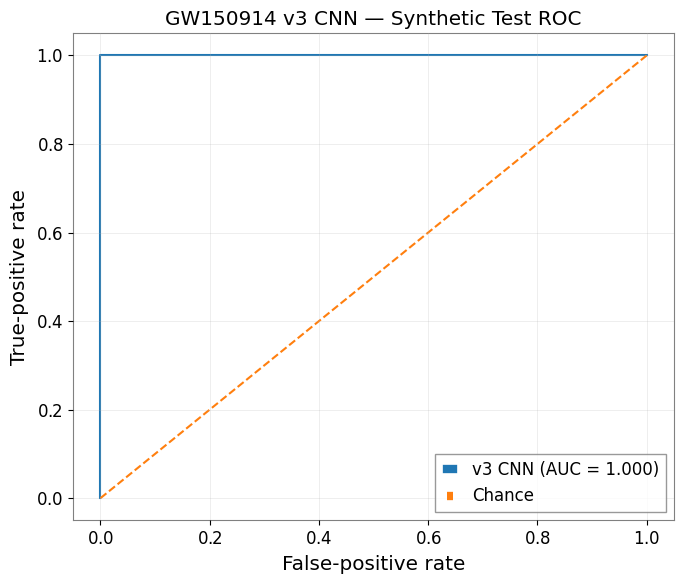

PHASE 11A COMPLETE
ROC figure: /content/gw150914_flagship/figures/phase11A_v3_roc.png
Evaluation report: /content/gw150914_flagship/reports/phase11A_v3_evaluation.json
Accuracy: 1.0
ROC-AUC: 1.0
Confusion matrix: [[30, 0], [0, 30]]


In [68]:

import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import (
    roc_curve, roc_auc_score, confusion_matrix,
    accuracy_score, classification_report
)

P = Path("/content/gw150914_flagship")
DATA, MODELS, REPORTS, FIGURES = (
    P/"dataset", P/"models", P/"reports", P/"figures"
)
for folder in [REPORTS, FIGURES]:
    folder.mkdir(exist_ok=True)

with np.load(DATA / "gw150914_test_v3.npz") as z:
    X, y = z["X"].astype("float32"), z["y"].astype(int)

model = tf.keras.models.load_model(MODELS / "gw150914_cnn_v3.keras")
X_model = np.transpose(X, (0, 2, 1))
scores = model.predict(X_model, batch_size=16, verbose=0).ravel()
pred = (scores >= 0.5).astype(int)

fpr, tpr, thresholds = roc_curve(y, scores)
auc = roc_auc_score(y, scores)
cm = confusion_matrix(y, pred)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"v3 CNN (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("GW150914 v3 CNN — Synthetic Test ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES / "phase11A_v3_roc.png", dpi=160)
plt.show()

results = {
    "dataset": "gw150914_v3",
    "test_examples": int(len(y)),
    "accuracy": float(accuracy_score(y, pred)),
    "roc_auc": float(auc),
    "confusion_matrix": cm.tolist(),
    "classification_report": classification_report(
        y, pred, output_dict=True, zero_division=0
    ),
    "evaluation_note": (
        "Synthetic controlled-injection test only; not a calibrated "
        "false-alarm-rate or astrophysical detection result."
    )
}

with open(REPORTS / "phase11A_v3_evaluation.json", "w") as f:
    json.dump(results, f, indent=2)

print("PHASE 11A COMPLETE")
print("ROC figure:", FIGURES / "phase11A_v3_roc.png")
print("Evaluation report:", REPORTS / "phase11A_v3_evaluation.json")
print("Accuracy:", results["accuracy"])
print("ROC-AUC:", results["roc_auc"])
print("Confusion matrix:", cm.tolist())


# Detection efficiency versus injection strength

In [70]:

import json
from pathlib import Path

P = Path("/content/gw150914_flagship")
REPORTS = P / "reports"

for split in ["train", "validation", "test"]:
    path = REPORTS / f"gw150914_{split}_v2_metadata.json"
    print(f"\n--- {split.upper()} ---")
    print("Metadata exists:", path.exists())

    if not path.exists():
        continue

    with open(path) as f:
        meta = json.load(f)

    print("Data type:", type(meta).__name__)

    if isinstance(meta, list):
        print("Number of records:", len(meta))
        if meta:
            print("First record:")
            print(json.dumps(meta[0], indent=2)[:2000])
            if len(meta) > 1:
                print("Second record keys/type:",
                      list(meta[1].keys())
                      if isinstance(meta[1], dict)
                      else type(meta[1]).__name__)

    elif isinstance(meta, dict):
        print("Top-level keys:", list(meta.keys()))
        print(json.dumps(meta, indent=2)[:2000])

print("\nMETADATA INSPECTION COMPLETE")




--- TRAIN ---
Metadata exists: True
Data type: list
Number of records: 100
First record:
{
  "offset": 600,
  "start_sample": 501349,
  "mass1": 44.358392807586185,
  "mass2": 20.508015890146964,
  "target_amplitude_scale": 4.658802314208206,
  "pair_id": 0
}
Second record keys/type: ['offset', 'start_sample', 'mass1', 'mass2', 'target_amplitude_scale', 'pair_id']

--- VALIDATION ---
Metadata exists: True
Data type: list
Number of records: 30
First record:
{
  "offset": 900,
  "start_sample": 193227,
  "mass1": 42.55395085254845,
  "mass2": 33.691827377823245,
  "target_amplitude_scale": 7.988572158915824,
  "pair_id": 0
}
Second record keys/type: ['offset', 'start_sample', 'mass1', 'mass2', 'target_amplitude_scale', 'pair_id']

--- TEST ---
Metadata exists: True
Data type: list
Number of records: 30
First record:
{
  "offset": 1200,
  "start_sample": 216970,
  "mass1": 33.06598631778406,
  "mass2": 29.088893855336778,
  "target_amplitude_scale": 6.0959536887392884,
  "pair_id": 0
}
S

## Detection performance by amplitude scale

In [71]:

import json
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import roc_auc_score, accuracy_score

P = Path("/content/gw150914_flagship")
REPORTS = P / "reports"
DATA = P / "dataset"
MODEL = P / "models" / "gw150914_cnn_v3.keras"

# Load test data and its recorded injection metadata
with np.load(DATA / "gw150914_test_v3.npz") as z:
    X, y = z["X"].astype("float32"), z["y"].astype(int)

with open(REPORTS / "gw150914_test_v2_metadata.json") as f:
    metadata = json.load(f)

# Metadata describes injected examples; pair_id links each clean/injected pair.
scales = {int(m["pair_id"]): float(m["target_amplitude_scale"])
          for m in metadata}

model = tf.keras.models.load_model(MODEL, compile=False)
scores = model.predict(np.transpose(X, (0, 2, 1)),
                       batch_size=16, verbose=0).ravel()

# Check sample ordering before associating pair IDs with predictions.
print("Test samples:", len(y))
print("Metadata records:", len(metadata))
print("Class counts:", np.bincount(y).tolist())
print("Recorded scale range:",
      round(min(scales.values()), 3), "to",
      round(max(scales.values()), 3))

# Existing dataset construction stores clean/injected pairs.
# Verify labels follow the expected pair ordering.
if len(y) != 2 * len(metadata):
    raise ValueError("Metadata/sample count mismatch; stopping safely.")

expected_y = np.tile([0, 1], len(metadata))
if not np.array_equal(y, expected_y):
    raise ValueError(
        "Labels are not in expected clean/injected pair order. "
        "Do not associate metadata until ordering is verified."
    )

# Summarize injected-example detection by recorded amplitude scale.
edges = np.linspace(min(scales.values()), max(scales.values()), 4)
rows = []

for lo, hi in zip(edges[:-1], edges[1:]):
    ids = [i for i, m in enumerate(metadata)
           if lo <= float(m["target_amplitude_scale"]) <= hi
           and (float(m["target_amplitude_scale"]) < hi
                or hi == edges[-1])]

    if not ids:
        continue

    injected_scores = np.array([scores[2*i + 1] for i in ids])
    clean_scores = np.array([scores[2*i] for i in ids])

    rows.append({
        "scale_range": [round(float(lo), 3), round(float(hi), 3)],
        "injections": len(ids),
        "injected_median_probability": float(np.median(injected_scores)),
        "injected_detected_at_0.5": int(np.sum(injected_scores >= 0.5)),
        "clean_false_positives_at_0.5": int(np.sum(clean_scores >= 0.5))
    })

print("\nResults by recorded amplitude scale:")
print(json.dumps(rows, indent=2))

out = REPORTS / "phase11B_scale_diagnostic.json"
with open(out, "w") as f:
    json.dump({
        "note": "Recorded amplitude scale, not calibrated physical SNR.",
        "results": rows
    }, f, indent=2)

print("\nSaved:", out)
print("PHASE 11B COMPLETE")


Test samples: 60
Metadata records: 30
Class counts: [30, 30]
Recorded scale range: 2.073 to 7.944

Results by recorded amplitude scale:
[
  {
    "scale_range": [
      2.073,
      4.03
    ],
    "injections": 8,
    "injected_median_probability": 0.9788357019424438,
    "injected_detected_at_0.5": 8,
    "clean_false_positives_at_0.5": 0
  },
  {
    "scale_range": [
      4.03,
      5.987
    ],
    "injections": 11,
    "injected_median_probability": 0.9998509287834167,
    "injected_detected_at_0.5": 11,
    "clean_false_positives_at_0.5": 0
  },
  {
    "scale_range": [
      5.987,
      7.944
    ],
    "injections": 11,
    "injected_median_probability": 0.9999658465385437,
    "injected_detected_at_0.5": 11,
    "clean_false_positives_at_0.5": 0
  }
]

Saved: /content/gw150914_flagship/reports/phase11B_scale_diagnostic.json
PHASE 11B COMPLETE


## Test whether the CNN relies on waveform structure

In [72]:

import json
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score, roc_auc_score

P = Path("/content/gw150914_flagship")

with np.load(P / "dataset/gw150914_test_v3.npz") as z:
    X = z["X"].astype("float32")
    y = z["y"].astype(int)

model = tf.keras.models.load_model(
    P / "models/gw150914_cnn_v3.keras",
    compile=False
)

rng = np.random.default_rng(2026)

# Randomize Fourier phase independently per example and detector,
# preserving Fourier magnitudes and producing real-valued signals.
F = np.fft.rfft(X, axis=-1)
mag = np.abs(F)
phase = rng.uniform(0, 2*np.pi, size=F.shape)
phase[..., 0] = np.angle(F[..., 0])

if X.shape[-1] % 2 == 0:
    phase[..., -1] = np.angle(F[..., -1])

F_random = mag * np.exp(1j * phase)
X_random = np.fft.irfft(F_random, n=X.shape[-1], axis=-1)
X_random = X_random.astype("float32")

# Normalize each channel again, matching v3 preprocessing.
X_random -= X_random.mean(axis=-1, keepdims=True)
X_random /= X_random.std(axis=-1, keepdims=True) + 1e-8

scores = model.predict(
    np.transpose(X_random, (0, 2, 1)),
    batch_size=16,
    verbose=0
).ravel()

pred = (scores >= 0.5).astype(int)

result = {
    "diagnostic": "randomized Fourier phase",
    "accuracy": float(accuracy_score(y, pred)),
    "roc_auc": float(roc_auc_score(y, scores)),
    "clean_median_probability": float(np.median(scores[y == 0])),
    "injected_median_probability": float(np.median(scores[y == 1])),
    "warning": (
        "This is an out-of-distribution diagnostic, not a standalone "
        "proof of waveform learning or astrophysical detection."
    )
}

out = P / "reports/phase11C_phase_randomization.json"
with open(out, "w") as f:
    json.dump(result, f, indent=2)

print(json.dumps(result, indent=2))
print("Saved:", out)
print("PHASE 11C COMPLETE")


{
  "diagnostic": "randomized Fourier phase",
  "accuracy": 0.9333333333333333,
  "roc_auc": 0.9966666666666667,
  "clean_median_probability": 0.022795630618929863,
  "injected_median_probability": 0.9999057054519653,
  "warning": "This is an out-of-distribution diagnostic, not a standalone proof of waveform learning or astrophysical detection."
}
Saved: /content/gw150914_flagship/reports/phase11C_phase_randomization.json
PHASE 11C COMPLETE


## Frequency-spectrum-only baseline

In [73]:

import json
import numpy as np
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

P = Path("/content/gw150914_flagship")

def load_split(name):
    with np.load(P / f"dataset/gw150914_{name}_v3.npz") as z:
        return z["X"].astype("float32"), z["y"].astype(int)

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

# Use only Fourier magnitudes, discarding phase and temporal ordering.
def spectral_features(X):
    F = np.abs(np.fft.rfft(X, axis=-1))
    # Average log-magnitude within 64 frequency bins per detector.
    F = np.log1p(F)
    chunks = np.array_split(F, 64, axis=-1)
    return np.concatenate([c.mean(axis=-1) for c in chunks], axis=1)

A = spectral_features(X_train)
B = spectral_features(X_val)
C = spectral_features(X_test)

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=2026)
)
baseline.fit(A, y_train)

val_scores = baseline.predict_proba(B)[:, 1]
test_scores = baseline.predict_proba(C)[:, 1]
test_pred = (test_scores >= 0.5).astype(int)

result = {
    "baseline": "logistic regression on binned Fourier magnitudes",
    "validation_accuracy": float(
        accuracy_score(y_val, (val_scores >= 0.5).astype(int))
    ),
    "validation_auc": float(roc_auc_score(y_val, val_scores)),
    "test_accuracy": float(accuracy_score(y_test, test_pred)),
    "test_auc": float(roc_auc_score(y_test, test_scores)),
    "test_examples": int(len(y_test)),
    "note": "Synthetic controlled-injection dataset; not astrophysical validation."
}

out = P / "reports/phase11D_spectral_baseline.json"
with open(out, "w") as f:
    json.dump(result, f, indent=2)

print(json.dumps(result, indent=2))
print("Saved:", out)
print("PHASE 11D COMPLETE")


{
  "baseline": "logistic regression on binned Fourier magnitudes",
  "validation_accuracy": 0.8666666666666667,
  "validation_auc": 0.9577777777777778,
  "test_accuracy": 0.95,
  "test_auc": 0.9633333333333333,
  "test_examples": 60,
  "note": "Synthetic controlled-injection dataset; not astrophysical validation."
}
Saved: /content/gw150914_flagship/reports/phase11D_spectral_baseline.json
PHASE 11D COMPLETE


## Compare models consistently

In [74]:

import json
from pathlib import Path

P = Path("/content/gw150914_flagship")
R = P / "reports"

files = {
    "cnn_test": "phase10C_cnn_v3_results.json",
    "cnn_evaluation": "phase11A_v3_evaluation.json",
    "amplitude_scale": "phase11B_scale_diagnostic.json",
    "phase_randomization": "phase11C_phase_randomization.json",
    "spectral_baseline": "phase11D_spectral_baseline.json",
}

report = {
    "project": "GW150914 synthetic classification prototype",
    "scientific_caveat": (
        "Controlled synthetic injections only. Results are not a calibrated "
        "false-alarm rate, physical-SNR efficiency curve, or validated "
        "astrophysical detection."
    ),
    "results": {}
}

for name, filename in files.items():
    path = R / filename
    if path.exists():
        with open(path) as f:
            report["results"][name] = json.load(f)
    else:
        report["results"][name] = {"status": "missing", "file": filename}

out = R / "phase11E_consolidated_report.json"
with open(out, "w") as f:
    json.dump(report, f, indent=2)

print("PHASE 11E COMPLETE")
print("Report:", out)
print("\nAvailable sections:")
for name, value in report["results"].items():
    print(f"- {name}:",
          "loaded" if "status" not in value else value["status"])
print("\nScientific caveat:", report["scientific_caveat"])


PHASE 11E COMPLETE
Report: /content/gw150914_flagship/reports/phase11E_consolidated_report.json

Available sections:
- cnn_test: loaded
- cnn_evaluation: loaded
- amplitude_scale: loaded
- phase_randomization: loaded
- spectral_baseline: loaded

Scientific caveat: Controlled synthetic injections only. Results are not a calibrated false-alarm rate, physical-SNR efficiency curve, or validated astrophysical detection.


## Compare models consistently

In [75]:

import json
from pathlib import Path

P = Path("/content/gw150914_flagship")
R = P / "reports"

files = {
    "cnn_test": "phase10C_cnn_v3_results.json",
    "cnn_evaluation": "phase11A_v3_evaluation.json",
    "amplitude_scale": "phase11B_scale_diagnostic.json",
    "phase_randomization": "phase11C_phase_randomization.json",
    "spectral_baseline": "phase11D_spectral_baseline.json",
}

report = {
    "project": "GW150914 synthetic classification prototype",
    "scientific_caveat": (
        "Controlled synthetic injections only. Results are not a calibrated "
        "false-alarm rate, physical-SNR efficiency curve, or validated "
        "astrophysical detection."
    ),
    "results": {}
}

for name, filename in files.items():
    path = R / filename
    if path.exists():
        with open(path) as f:
            report["results"][name] = json.load(f)
    else:
        report["results"][name] = {"status": "missing", "file": filename}

out = R / "phase11E_consolidated_report.json"
with open(out, "w") as f:
    json.dump(report, f, indent=2)

print("PHASE 11E COMPLETE")
print("Report:", out)
print("\nAvailable sections:")
for name, value in report["results"].items():
    print(f"- {name}:",
          "loaded" if "status" not in value else value["status"])
print("\nScientific caveat:", report["scientific_caveat"])


PHASE 11E COMPLETE
Report: /content/gw150914_flagship/reports/phase11E_consolidated_report.json

Available sections:
- cnn_test: loaded
- cnn_evaluation: loaded
- amplitude_scale: loaded
- phase_randomization: loaded
- spectral_baseline: loaded

Scientific caveat: Controlled synthetic injections only. Results are not a calibrated false-alarm rate, physical-SNR efficiency curve, or validated astrophysical detection.


## Independent-background audit

In [76]:

import json
from pathlib import Path

P = Path("/content/gw150914_flagship")
R = P / "reports"
background_length = 16384  # samples per example

split_offsets = {}
split_windows = {}
audit = {}

for split in ["train", "validation", "test"]:
    path = R / f"gw150914_{split}_v2_metadata.json"
    with open(path) as f:
        records = json.load(f)

    offsets = {int(r["offset"]) for r in records}
    windows = [
        (int(r["offset"]), int(r["start_sample"]),
         int(r["start_sample"]) + background_length)
        for r in records
    ]

    split_offsets[split] = offsets
    split_windows[split] = windows

    audit[split] = {
        "records": len(records),
        "offsets_seconds": sorted(offsets),
        "unique_pair_ids": len({r["pair_id"] for r in records}),
        "unique_windows": len(set(windows))
    }

# Check whether different splits reuse any recorded noise window.
overlaps = []
for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    shared = set(split_windows[a]) & set(split_windows[b])
    overlaps.append({
        "splits": [a, b],
        "shared_windows": len(shared)
    })

offsets_disjoint = all(
    split_offsets[a].isdisjoint(split_offsets[b])
    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test")
    ]
)

report = {
    "split_audit": audit,
    "window_overlap_checks": overlaps,
    "offset_sets_disjoint": offsets_disjoint,
    "interpretation": (
        "Metadata-level audit only; distinct offsets do not prove "
        "independent detector noise or realistic astrophysical injections."
    )
}

out = R / "phase12A_background_audit.json"
with open(out, "w") as f:
    json.dump(report, f, indent=2)

print(json.dumps(report, indent=2))
print("\nPHASE 12A COMPLETE")
print("Saved:", out)


{
  "split_audit": {
    "train": {
      "records": 100,
      "offsets_seconds": [
        300,
        600
      ],
      "unique_pair_ids": 100,
      "unique_windows": 100
    },
    "validation": {
      "records": 30,
      "offsets_seconds": [
        900
      ],
      "unique_pair_ids": 30,
      "unique_windows": 30
    },
    "test": {
      "records": 30,
      "offsets_seconds": [
        1200
      ],
      "unique_pair_ids": 30,
      "unique_windows": 30
    }
  },
  "window_overlap_checks": [
    {
      "splits": [
        "train",
        "validation"
      ],
      "shared_windows": 0
    },
    {
      "splits": [
        "train",
        "test"
      ],
      "shared_windows": 0
    },
    {
      "splits": [
        "validation",
        "test"
      ],
      "shared_windows": 0
    }
  ],
  "offset_sets_disjoint": true,
  "interpretation": "Metadata-level audit only; distinct offsets do not prove independent detector noise or realistic astrophysical injections.

## Verify the actual background windows

In [77]:

import json
import numpy as np
from pathlib import Path

P = Path("/content/gw150914_flagship")
RAW = P / "raw"
REPORTS = P / "reports"

audit = []
window_length = 16384

for split in ["train", "validation", "test"]:
    with open(REPORTS / f"gw150914_{split}_v2_metadata.json") as f:
        records = json.load(f)

    for r in records:
        offset = int(r["offset"])
        start = int(r["start_sample"])
        end = start + window_length

        for detector in ["H1", "L1"]:
            path = RAW / f"{detector}_background_offset_{offset}s.npy"

            if not path.exists():
                audit.append({
                    "split": split, "offset": offset,
                    "detector": detector, "status": "MISSING_FILE"
                })
                continue

            arr = np.load(path, mmap_mode="r")
            valid = 0 <= start < end <= len(arr)

            audit.append({
                "split": split,
                "offset": offset,
                "detector": detector,
                "file_samples": int(len(arr)),
                "start": start,
                "end": end,
                "in_bounds": bool(valid),
                "status": "OK" if valid else "OUT_OF_BOUNDS"
            })

summary = {
    "windows_checked": len(audit),
    "all_in_bounds": all(x.get("in_bounds", False) for x in audit),
    "missing_files": sum(x["status"] == "MISSING_FILE" for x in audit),
    "out_of_bounds": sum(x["status"] == "OUT_OF_BOUNDS" for x in audit)
}

out = REPORTS / "phase12B_window_bounds_audit.json"
with open(out, "w") as f:
    json.dump({"summary": summary, "details": audit}, f, indent=2)

print(json.dumps(summary, indent=2))
print("Saved:", out)
print("PHASE 12B COMPLETE")


{
  "windows_checked": 320,
  "all_in_bounds": true,
  "missing_files": 0,
  "out_of_bounds": 0
}
Saved: /content/gw150914_flagship/reports/phase12B_window_bounds_audit.json
PHASE 12B COMPLETE


## Check H1/L1 background quality

In [78]:

import json
import numpy as np
from pathlib import Path

P = Path("/content/gw150914_flagship")
RAW = P / "raw"
REPORTS = P / "reports"

offsets = [300, 600, 900, 1200]
results = []

for detector in ["H1", "L1"]:
    for offset in offsets:
        path = RAW / f"{detector}_background_offset_{offset}s.npy"
        x = np.load(path, mmap_mode="r")

        # Inspect finite values and robust amplitude statistics.
        finite = np.isfinite(x)
        if not finite.all():
            results.append({
                "detector": detector,
                "offset": offset,
                "samples": int(len(x)),
                "finite_fraction": float(finite.mean()),
                "status": "NON_FINITE_VALUES"
            })
            continue

        sample = np.asarray(x, dtype=np.float64)
        median = float(np.median(sample))
        mad = float(np.median(np.abs(sample - median)))
        std = float(np.std(sample))
        max_abs = float(np.max(np.abs(sample)))
        peak_to_std = max_abs / (std + 1e-12)
        robust_z_max = (
            max_abs / (1.4826 * mad + 1e-12)
        )

        results.append({
            "detector": detector,
            "offset": offset,
            "samples": int(len(sample)),
            "mean": float(np.mean(sample)),
            "std": std,
            "median": median,
            "mad": mad,
            "max_abs": max_abs,
            "peak_to_std": float(peak_to_std),
            "robust_z_max": float(robust_z_max),
            "status": "FINITE"
        })

out = REPORTS / "phase12C_background_quality.json"
with open(out, "w") as f:
    json.dump(results, f, indent=2)

for r in results:
    print(
        r["detector"], "offset", r["offset"],
        "| status:", r["status"],
        "| std:", r.get("std"),
        "| peak/std:", r.get("peak_to_std")
    )

print("\nSaved:", out)
print("PHASE 12C COMPLETE")


H1 offset 300 | status: FINITE | std: 2.117184798259351e-19 | peak/std: 9.454547997802825e-07
H1 offset 600 | status: FINITE | std: 2.1052483625696043e-19 | peak/std: 1.0714750777098875e-06
H1 offset 900 | status: FINITE | std: 2.026516741067117e-19 | peak/std: 7.899368113951389e-07
H1 offset 1200 | status: FINITE | std: 2.115493160034502e-19 | peak/std: 8.476397505412694e-07
L1 offset 300 | status: FINITE | std: 2.250296740139541e-19 | peak/std: 2.1030945040337926e-06
L1 offset 600 | status: FINITE | std: 2.327556257474626e-19 | peak/std: 2.403599966223454e-06
L1 offset 900 | status: FINITE | std: 2.1672752481753705e-19 | peak/std: 2.067970151882525e-06
L1 offset 1200 | status: FINITE | std: 2.072313928105674e-19 | peak/std: 1.9082410801101415e-06

Saved: /content/gw150914_flagship/reports/phase12C_background_quality.json
PHASE 12C COMPLETE


## Verify amplitude statistics

In [79]:

import numpy as np
from pathlib import Path

RAW = Path("/content/gw150914_flagship/raw")

for detector in ["H1", "L1"]:
    for offset in [300, 600, 900, 1200]:
        path = RAW / f"{detector}_background_offset_{offset}s.npy"
        x = np.asarray(np.load(path, mmap_mode="r"), dtype=np.float64)

        std = np.std(x)
        peak = np.max(np.abs(x))

        print(
            f"{detector} offset={offset}s | "
            f"min={np.min(x):.6e} | "
            f"max={np.max(x):.6e} | "
            f"std={std:.6e} | "
            f"peak/std={peak / (std + 1e-300):.6f}"
        )

print("\nPHASE 12D COMPLETE")


H1 offset=300s | min=-8.721986e-19 | max=9.454550e-19 | std=2.117185e-19 | peak/std=4.465623
H1 offset=600s | min=-1.071475e-18 | max=1.062863e-18 | std=2.105248e-19 | peak/std=5.089543
H1 offset=900s | min=-7.652439e-19 | max=7.899370e-19 | std=2.026517e-19 | peak/std=3.898004
H1 offset=1200s | min=-8.476399e-19 | max=8.146851e-19 | std=2.115493e-19 | peak/std=4.006820
L1 offset=300s | min=-2.103095e-18 | max=7.716889e-20 | std=2.250297e-19 | peak/std=9.345856
L1 offset=600s | min=-2.403601e-18 | max=1.997513e-19 | std=2.327556e-19 | peak/std=10.326713
L1 offset=900s | min=-2.067971e-18 | max=-1.181029e-20 | std=2.167275e-19 | peak/std=9.541800
L1 offset=1200s | min=-1.908241e-18 | max=-9.853759e-20 | std=2.072314e-19 | peak/std=9.208264

PHASE 12D COMPLETE


## Check detector offsets and signal distribution

In [80]:

import json
import numpy as np
from pathlib import Path

RAW = Path("/content/gw150914_flagship/raw")
REPORTS = Path("/content/gw150914_flagship/reports")

results = []

for detector in ["H1", "L1"]:
    for offset in [300, 600, 900, 1200]:
        path = RAW / f"{detector}_background_offset_{offset}s.npy"
        x = np.asarray(np.load(path, mmap_mode="r"), dtype=np.float64)

        mean = float(np.mean(x))
        std = float(np.std(x))
        median = float(np.median(x))

        results.append({
            "detector": detector,
            "offset": offset,
            "mean": mean,
            "median": median,
            "std": std,
            "mean_over_std": mean / (std + 1e-300),
            "median_over_std": median / (std + 1e-300),
            "positive_fraction": float(np.mean(x > 0)),
            "negative_fraction": float(np.mean(x < 0))
        })

for r in results:
    print(
        f"{r['detector']} {r['offset']}s | "
        f"mean/std={r['mean_over_std']:.4f} | "
        f"median/std={r['median_over_std']:.4f} | "
        f"positive={r['positive_fraction']:.3f} | "
        f"negative={r['negative_fraction']:.3f}"
    )

out = REPORTS / "phase12E_offset_diagnostic.json"
with open(out, "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved:", out)
print("PHASE 12E COMPLETE")


H1 300s | mean/std=0.0003 | median/std=0.0004 | positive=0.500 | negative=0.500
H1 600s | mean/std=-0.0005 | median/std=-0.0078 | positive=0.496 | negative=0.504
H1 900s | mean/std=0.0005 | median/std=0.0074 | positive=0.503 | negative=0.497
H1 1200s | mean/std=0.0012 | median/std=0.0066 | positive=0.503 | negative=0.497
L1 300s | mean/std=-4.7060 | median/std=-4.7036 | positive=0.000 | negative=1.000
L1 600s | mean/std=-4.5361 | median/std=-4.5325 | positive=0.001 | negative=0.999
L1 900s | mean/std=-4.8437 | median/std=-4.8427 | positive=0.000 | negative=1.000
L1 1200s | mean/std=-5.0685 | median/std=-5.0766 | positive=0.000 | negative=1.000

Saved: /content/gw150914_flagship/reports/phase12E_offset_diagnostic.json
PHASE 12E COMPLETE


## Trace the L1 offset to its source

In [81]:

import numpy as np
from pathlib import Path

P = Path("/content/gw150914_flagship")

print("Available raw files:")
for p in sorted((P / "raw").glob("*.npy")):
    print(" ", p.name)

print("\n--- Raw background versus processed strain ---")

checks = [
    P / "raw/L1_background_offset_300s.npy",
    P / "raw/L1_background_offset_600s.npy",
    P / "raw/H1_background_offset_300s.npy",
    P / "processed/L1_GW150914_whitened.npy",
    P / "processed/H1_GW150914_whitened.npy",
]

for path in checks:
    if not path.exists():
        print("\nMISSING:", path.name)
        continue

    x = np.asarray(np.load(path, mmap_mode="r"), dtype=np.float64)
    print(f"\n{path.name}")
    print("Shape:", x.shape, "| dtype:", x.dtype)
    print("Mean:", f"{np.mean(x):.6e}")
    print("Std:", f"{np.std(x):.6e}")
    print("Min/max:", f"{np.min(x):.6e}", f"{np.max(x):.6e}")
    print("First 8 samples:", np.array2string(x[:8], precision=5))

print("\nPHASE 12F COMPLETE")


Available raw files:
  H1_GW150914_raw.npy
  H1_background_offset_1200s.npy
  H1_background_offset_300s.npy
  H1_background_offset_600s.npy
  H1_background_offset_900s.npy
  L1_GW150914_raw.npy
  L1_background_offset_1200s.npy
  L1_background_offset_300s.npy
  L1_background_offset_600s.npy
  L1_background_offset_900s.npy

--- Raw background versus processed strain ---

L1_background_offset_300s.npy
Shape: (524288,) | dtype: float64
Mean: -1.058983e-18
Std: 2.250297e-19
Min/max: -2.103095e-18 7.716889e-20
First 8 samples: [-1.22845e-18 -1.24963e-18 -1.25047e-18 -1.23282e-18
 -1.21439e-18 -1.19087e-18 -1.16873e-18 -1.18092e-18]

L1_background_offset_600s.npy
Shape: (524288,) | dtype: float64
Mean: -1.055801e-18
Std: 2.327556e-19
Min/max: -2.403601e-18 1.997513e-19
First 8 samples: [-8.34288e-19 -8.37165e-19 -8.71538e-19 -8.74954e-19
 -8.73717e-19 -9.05747e-19 -9.19350e-19 -8.93519e-19]

H1_background_offset_300s.npy
Shape: (524288,) | dtype: float64
Mean: 6.316695e-23
Std: 2.117185e-19
M

In [82]:

from pathlib import Path
import json

P = Path("/content/gw150914_flagship")

terms = [
    "L1_background_offset",
    "background_offset",
    "TimeSeries.fetch",
    "fetch_open_data",
    "GWOSC",
    "1126259462.4"
]

print("Searching project notebooks and Python scripts...\n")

files = list(P.rglob("*.ipynb")) + list(P.rglob("*.py"))
matches = 0

for path in files:
    try:
        if path.suffix == ".ipynb":
            notebook = json.loads(path.read_text())
            cells = [
                "".join(c.get("source", []))
                for c in notebook.get("cells", [])
            ]
        else:
            cells = path.read_text(errors="ignore").split("\n\n")

        for i, source in enumerate(cells):
            found = [term for term in terms if term in source]
            if found:
                matches += 1
                print(f"\nFILE: {path}")
                print(f"CELL/SECTION: {i}")
                print(f"MATCHES: {found}")
                print(source[:3500])

    except Exception as e:
        print("Skipped:", path.name, type(e).__name__)

if matches == 0:
    print("No matching notebook or Python source found in the project.")

print("\nPHASE 12G COMPLETE | matching sections:", matches)


Searching project notebooks and Python scripts...

No matching notebook or Python source found in the project.

PHASE 12G COMPLETE | matching sections: 0


In [83]:

from IPython import get_ipython

ip = get_ipython()
terms = [
    "L1_background_offset",
    "background_offset",
    "fetch_open_data",
    "TimeSeries.fetch",
    "gwosc",
    "strain"
]

history = list(ip.history_manager.get_range(
    session=0, start=1, stop=None, raw=True
))

matches = []
for session, line, source in history:
    if any(term.lower() in source.lower() for term in terms):
        matches.append((line, source))

print("Matching history entries:", len(matches))

for line, source in matches[-12:]:
    print(f"\n--- CELL {line} ---")
    print(source[:2500])

if not matches:
    print(
        "\nNo matching commands in persistent history. "
        "We can inspect the raw arrays and acquisition metadata next."
    )

print("\nPHASE 12H COMPLETE")


Matching history entries: 40

--- CELL 54 ---

import json
import numpy as np
from pathlib import Path

PROJECT = Path("/content/gw150914_flagship")
REPORTS = PROJECT / "reports"

for split in ["train", "validation", "test"]:
    path = REPORTS / f"gw150914_{split}_v1_metadata.json"
    with open(path) as f:
        rows = json.load(f)

    pos = [r for r in rows if r["label"] == 1]
    snrs = np.array([
        r["target_network_snr_estimate"] for r in pos
    ])

    print(f"\n{split.upper()}")
    print("Positive examples:", len(pos))
    print("Target SNR min/median/max:",
          round(float(snrs.min()), 2),
          round(float(np.median(snrs)), 2),
          round(float(snrs.max()), 2))
    print("First 3 injections:")
    for row in pos[:3]:
        print({
            k: row.get(k) for k in [
                "background_offset_seconds",
                "mass1_solar",
                "mass2_solar",
                "target_network_snr_estimate",
            ]
        })

--- 

In [85]:

from IPython import get_ipython

ip = get_ipython()
history = list(ip.history_manager.get_range(
    session=0, start=1, stop=None, raw=True
))

matches = []
for session, line, source in history[-150:]:
    if any(term in source.lower() for term in [
        "np.save(", "background_offset_",
        "fetch_open_data", "timeseries.fetch", "gwosc"
    ]):
        matches.append((line, source))

print("Matching extraction entries:", len(matches))

for line, source in matches[-8:]:
    print(f"\n--- CELL {line} ---")
    print(source[:2000])

print("\nEXTRACTION HISTORY CHECK COMPLETE")


Matching extraction entries: 40

--- CELL 78 ---

import json
import numpy as np
from pathlib import Path

P = Path("/content/gw150914_flagship")
RAW = P / "raw"
REPORTS = P / "reports"

offsets = [300, 600, 900, 1200]
results = []

for detector in ["H1", "L1"]:
    for offset in offsets:
        path = RAW / f"{detector}_background_offset_{offset}s.npy"
        x = np.load(path, mmap_mode="r")

        # Inspect finite values and robust amplitude statistics.
        finite = np.isfinite(x)
        if not finite.all():
            results.append({
                "detector": detector,
                "offset": offset,
                "samples": int(len(x)),
                "finite_fraction": float(finite.mean()),
                "status": "NON_FINITE_VALUES"
            })
            continue

        sample = np.asarray(x, dtype=np.float64)
        median = float(np.median(sample))
        mad = float(np.median(np.abs(sample - median)))
        std = float(np.std(sample))
        max

In [86]:
from pathlib import Path

P = Path("/content/gw150914_flagship")

print("PROJECT:", P.exists())
print("\nDOCUMENTATION:")
for f in sorted(P.rglob("*")):
    if f.is_file() and (
        f.name.lower().startswith("readme")
        or f.suffix.lower() in {".md", ".pdf"}
    ):
        print(f.relative_to(P))

print("\nKEY REPORTS:")
for name in [
    "phase11E_consolidated_report.json",
    "phase12A_background_audit.json",
    "phase12B_window_bounds_audit.json",
    "phase12E_offset_diagnostic.json",
    "matched_filter_baseline.json",
]:
    matches = list(P.rglob(name))
    print(f"{name}: {'FOUND' if matches else 'MISSING'}")

print("\nPORTFOLIO CHECK COMPLETE")

PROJECT: True

DOCUMENTATION:

KEY REPORTS:
phase11E_consolidated_report.json: FOUND
phase12A_background_audit.json: FOUND
phase12B_window_bounds_audit.json: FOUND
phase12E_offset_diagnostic.json: FOUND
matched_filter_baseline.json: FOUND

PORTFOLIO CHECK COMPLETE


## Real-event versus off-source noise

In [87]:

import json
import numpy as np
from pathlib import Path
from scipy.signal import butter, sosfiltfilt
from pycbc.types import TimeSeries
from pycbc.waveform import get_fd_waveform
from pycbc.filter import matched_filter
from pycbc.psd import welch

P = Path("/content/gw150914_flagship")
RAW, REPORTS = P / "raw", P / "reports"

FS = 4096
WIN = 4 * FS
BLOCK = 32 * FS
OFFSETS = [300, 600, 900, 1200]

sos = butter(4, [20, 500], btype="bandpass",
             fs=FS, output="sos")

hp, _ = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=40, mass2=32,
    spin1z=0, spin2z=0,
    delta_f=1 / 4,
    f_lower=20,
    f_final=500
)
hp.resize(WIN // 2 + 1)

def condition(x):
    x = np.asarray(x, dtype=np.float64)
    return sosfiltfilt(sos, x - np.mean(x))

def peak_snr(x, psd):
    peaks = []
    step = 2 * FS

    for start in range(0, len(x) - WIN + 1, step):
        chunk = x[start:start + WIN]
        data = TimeSeries(chunk, delta_t=1 / FS)
        snr = matched_filter(
            hp, data, psd=psd,
            low_frequency_cutoff=20,
            high_frequency_cutoff=500
        )
        values = np.asarray(abs(snr))
        peaks.append(float(np.max(values)))

    return max(peaks) if peaks else float("nan")

results = []

for det in ["H1", "L1"]:
    event_path = RAW / f"{det}_GW150914_raw.npy"
    if not event_path.exists():
        raise FileNotFoundError(event_path)

    event = condition(np.load(event_path))

    if len(event) < BLOCK:
        raise ValueError(f"{det} event data is shorter than 32 seconds.")

    event = event[:BLOCK]

    for offset in OFFSETS:
        path = RAW / f"{det}_background_offset_{offset}s.npy"
        if not path.exists():
            raise FileNotFoundError(path)

        bg = condition(np.load(path))

        psd = welch(
            TimeSeries(bg, delta_t=1 / FS),
            seg_len=WIN,
            seg_stride=WIN // 2
        )

        event_peak = peak_snr(event, psd)
        background_peaks = []

        for start in range(0, len(bg) - BLOCK + 1, BLOCK):
            block = bg[start:start + BLOCK]
            background_peaks.append(peak_snr(block, psd))

        result = {
            "detector": det,
            "background_offset_seconds": offset,
            "event_32s_peak_snr": event_peak,
            "background_32s_peak_snrs": background_peaks,
            "max_background_peak_snr": (
                max(background_peaks) if background_peaks else None
            ),
            "event_exceeds_all_tested_background_blocks": (
                bool(background_peaks)
                and event_peak > max(background_peaks)
            ),
            "interpretation": "Preliminary comparison; not calibrated significance"
        }
        results.append(result)

        print(
            f"{det} | offset={offset}s | "
            f"event peak={event_peak:.3f} | "
            f"largest background peak="
            f"{result['max_background_peak_snr']:.3f}"
            if background_peaks else
            f"{det} | offset={offset}s | no complete background blocks"
        )

out = REPORTS / "phase13A_event_vs_background.json"
with open(out, "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved:", out)
print("PHASE 13A COMPLETE")


H1 | offset=300s | event peak=103.202 | largest background peak=83.507
H1 | offset=600s | event peak=98.909 | largest background peak=74.233
H1 | offset=900s | event peak=99.281 | largest background peak=40.925
H1 | offset=1200s | event peak=102.643 | largest background peak=42.588
L1 | offset=300s | event peak=103.436 | largest background peak=88.846
L1 | offset=600s | event peak=108.277 | largest background peak=137.351
L1 | offset=900s | event peak=105.593 | largest background peak=27.195
L1 | offset=1200s | event peak=102.585 | largest background peak=29.731

Saved: /content/gw150914_flagship/reports/phase13A_event_vs_background.json
PHASE 13A COMPLETE


## Check the discrepancy

In [88]:

import json
import numpy as np
from pathlib import Path

P = Path("/content/gw150914_flagship")
R = P / "reports"

with open(R / "matched_filter_baseline.json") as f:
    print("EARLIER MATCHED-FILTER BASELINE:")
    print(json.dumps(json.load(f), indent=2)[:2500])

print("\nSTRAIN SCALE CHECK:")
for name in [
    "raw/H1_GW150914_raw.npy",
    "raw/L1_GW150914_raw.npy",
    "processed/H1_GW150914_whitened.npy",
    "processed/L1_GW150914_whitened.npy",
]:
    x = np.load(P / name, mmap_mode="r")
    print(
        name,
        "| samples:", len(x),
        "| mean:", f"{np.mean(x):.5e}",
        "| std:", f"{np.std(x):.5e}",
        "| min/max:", f"{np.min(x):.5e}/{np.max(x):.5e}"
    )

print("\nPHASE 13B COMPLETE")


EARLIER MATCHED-FILTER BASELINE:
{
  "H1": {
    "approximant": "IMRPhenomD",
    "mass1_solar": 40.0,
    "mass2_solar": 32.0,
    "low_frequency_hz": 20.0,
    "high_frequency_hz": 500.0,
    "psd_source": "Median of four candidate off-source PSDs",
    "peak_snr_near_event": 19.994646947693845,
    "peak_gps_time": 1126259462.4280763,
    "peak_time_relative_to_reference_s": 0.028076171875,
    "search_window_seconds": [
      1126259462.2,
      1126259462.6000001
    ]
  },
  "L1": {
    "approximant": "IMRPhenomD",
    "mass1_solar": 40.0,
    "mass2_solar": 32.0,
    "low_frequency_hz": 20.0,
    "high_frequency_hz": 500.0,
    "psd_source": "Median of four candidate off-source PSDs",
    "peak_snr_near_event": 14.609528835586001,
    "peak_gps_time": 1126259462.4209962,
    "peak_time_relative_to_reference_s": 0.02099609375,
    "search_window_seconds": [
      1126259462.2,
      1126259462.6000001
    ]
  }
}

STRAIN SCALE CHECK:
raw/H1_GW150914_raw.npy | samples: 131072 | me

In [89]:

import numpy as np
from pathlib import Path

P = Path("/content/gw150914_flagship")
FS = 4096

for det in ["H1", "L1"]:
    path = P / f"processed/{det}_GW150914_whitened.npy"
    x = np.load(path)

    # Processed data covers 24 seconds from event GPS - 12 s.
    t = np.arange(len(x)) / FS - 12.0

    # Inspect the region around the known merger time.
    mask = (t >= -0.5) & (t <= 0.5)
    segment = x[mask]
    local_t = t[mask]

    peak_idx = int(np.argmax(np.abs(segment)))

    print(f"\n{det}")
    print("Samples:", len(x))
    print("Time range relative to event:", f"{t[0]:.3f} to {t[-1]:.3f} s")
    print("Largest absolute amplitude within ±0.5 s:",
          f"{np.max(np.abs(segment)):.4f}")
    print("Time of that peak:", f"{local_t[peak_idx]:+.6f} s")

print("\nPHASE 13C COMPLETE")



H1
Samples: 98304
Time range relative to event: -12.000 to 12.000 s
Largest absolute amplitude within ±0.5 s: 4.4425
Time of that peak: +0.023193 s

L1
Samples: 98304
Time range relative to event: -12.000 to 12.000 s
Largest absolute amplitude within ±0.5 s: 3.9319
Time of that peak: +0.018311 s

PHASE 13C COMPLETE


## Consistent matched-filter validation

In [90]:

import json
import numpy as np
from pathlib import Path
from scipy.signal import butter, sosfiltfilt
from pycbc.types import TimeSeries
from pycbc.waveform import get_fd_waveform
from pycbc.filter import matched_filter
from pycbc.psd import welch

P = Path("/content/gw150914_flagship")
RAW, REPORTS = P / "raw", P / "reports"

FS = 4096
WIN = 4 * FS
STRIDE = 2 * FS
sos = butter(4, [20, 500], btype="bandpass",
             fs=FS, output="sos")

def condition(x):
    x = np.asarray(x, dtype=np.float64)
    return sosfiltfilt(sos, x - np.mean(x))

def make_psd(x):
    return welch(
        TimeSeries(x, delta_t=1 / FS),
        seg_len=WIN,
        seg_stride=WIN // 2
    )

def peak_snr(x, psd):
    data = TimeSeries(x, delta_t=1 / FS)
    snr = matched_filter(
        template, data, psd=psd,
        low_frequency_cutoff=20,
        high_frequency_cutoff=500
    )
    return float(np.max(np.abs(np.asarray(snr))))

template, _ = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=40, mass2=32,
    spin1z=0, spin2z=0,
    delta_f=1 / 4,
    f_lower=20,
    f_final=500
)
template.resize(WIN // 2 + 1)

results = []

for det in ["H1", "L1"]:
    backgrounds = [
        condition(np.load(
            RAW / f"{det}_background_offset_{offset}s.npy"
        ))
        for offset in [300, 600, 900, 1200]
    ]

    psds = [make_psd(bg) for bg in backgrounds]
    median_psd = psds[0].copy()
    median_psd *= 0

    for psd in psds:
        median_psd += psd / len(psds)

    event = condition(np.load(RAW / f"{det}_GW150914_raw.npy"))

    # Raw event starts 16 seconds before the reference merger time.
    event_window = event[14 * FS:18 * FS]
    event_peak = peak_snr(event_window, median_psd)

    background_peaks = []
    for bg in backgrounds:
        for start in range(0, len(bg) - WIN + 1, STRIDE):
            background_peaks.append(
                peak_snr(bg[start:start + WIN], median_psd)
            )

    row = {
        "detector": det,
        "event_window_seconds_relative_to_reference": [-2, 2],
        "event_peak_snr": event_peak,
        "background_windows_tested": len(background_peaks),
        "background_median_peak_snr": float(np.median(background_peaks)),
        "background_95th_percentile": float(np.percentile(background_peaks, 95)),
        "background_max_peak_snr": float(np.max(background_peaks)),
        "event_exceeds_tested_background_max": bool(
            event_peak > np.max(background_peaks)
        )
    }
    results.append(row)

    print(f"\n{det}")
    for key, value in row.items():
        if key != "detector":
            print(f"{key}: {value}")

out = REPORTS / "phase13D_consistent_matched_filter.json"
with open(out, "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved:", out)
print("PHASE 13D COMPLETE")



H1
event_window_seconds_relative_to_reference: [-2, 2]
event_peak_snr: 20.26724304490105
background_windows_tested: 252
background_median_peak_snr: 11.070983218126447
background_95th_percentile: 16.969870070169957
background_max_peak_snr: 81.57253610674235
event_exceeds_tested_background_max: False

L1
event_window_seconds_relative_to_reference: [-2, 2]
event_peak_snr: 13.774398790008451
background_windows_tested: 252
background_median_peak_snr: 13.550198435970092
background_95th_percentile: 27.476259171720717
background_max_peak_snr: 131.62045566590217
event_exceeds_tested_background_max: False

Saved: /content/gw150914_flagship/reports/phase13D_consistent_matched_filter.json
PHASE 13D COMPLETE


## — Find the background outliers

In [92]:

import numpy as np
from pathlib import Path
from scipy.signal import butter, sosfiltfilt
from pycbc.types import TimeSeries
from pycbc.waveform import get_fd_waveform
from pycbc.filter import matched_filter
from pycbc.psd import welch

P = Path("/content/gw150914_flagship")
RAW = P / "raw"
FS, WIN, STRIDE = 4096, 4 * 4096, 2 * 4096
sos = butter(4, [20, 500], btype="bandpass",
             fs=FS, output="sos")

def condition(x):
    x = np.asarray(x, dtype=np.float64)
    return sosfiltfilt(sos, x - np.mean(x))

template, _ = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=40, mass2=32, spin1z=0, spin2z=0,
    delta_f=1/4, f_lower=20, f_final=500
)
template.resize(WIN // 2 + 1)

for det in ["H1", "L1"]:
    backgrounds = {
        off: condition(np.load(
            RAW / f"{det}_background_offset_{off}s.npy"
        ))
        for off in [300, 600, 900, 1200]
    }

    psds = [
        welch(TimeSeries(x, delta_t=1/FS),
              seg_len=WIN, seg_stride=WIN//2)
        for x in backgrounds.values()
    ]
    psd = psds[0].copy()
    psd *= 0
    for item in psds:
        psd += item / len(psds)

    peaks = []
    for off, x in backgrounds.items():
        for start in range(0, len(x) - WIN + 1, STRIDE):
            chunk = x[start:start+WIN]
            snr = matched_filter(
                template, TimeSeries(chunk, delta_t=1/FS),
                psd=psd, low_frequency_cutoff=20,
                high_frequency_cutoff=500
            )
            peak = float(np.max(np.abs(np.asarray(snr))))
            peaks.append((peak, off, start/FS,
                          float(np.std(chunk)),
                          float(np.max(np.abs(chunk)))))

    peaks.sort(reverse=True)
    print(f"\n{det} — TOP 5 BACKGROUND PEAKS")
    for peak, off, start, std, maxabs in peaks[:5]:
        print(
            f"offset={off}s | window_start={start:.1f}s | "
            f"peak_SNR={peak:.2f} | std={std:.3e} | "
            f"max_abs={maxabs:.3e}"
        )

print("\nPHASE 13E COMPLETE")



H1 — TOP 5 BACKGROUND PEAKS
offset=300s | window_start=124.0s | peak_SNR=81.57 | std=1.962e-21 | max_abs=4.771e-20
offset=600s | window_start=0.0s | peak_SNR=73.68 | std=2.131e-21 | max_abs=4.250e-20
offset=300s | window_start=0.0s | peak_SNR=56.26 | std=1.831e-21 | max_abs=2.958e-20
offset=900s | window_start=0.0s | peak_SNR=41.53 | std=1.736e-21 | max_abs=2.106e-20
offset=1200s | window_start=124.0s | peak_SNR=41.45 | std=1.703e-21 | max_abs=2.484e-20

L1 — TOP 5 BACKGROUND PEAKS
offset=600s | window_start=124.0s | peak_SNR=131.62 | std=1.357e-20 | max_abs=9.364e-20
offset=300s | window_start=124.0s | peak_SNR=88.87 | std=1.481e-20 | max_abs=6.500e-20
offset=600s | window_start=0.0s | peak_SNR=54.95 | std=1.150e-20 | max_abs=3.865e-20
offset=300s | window_start=80.0s | peak_SNR=32.27 | std=1.959e-20 | max_abs=4.606e-20
offset=300s | window_start=44.0s | peak_SNR=31.65 | std=1.812e-20 | max_abs=4.781e-20

PHASE 13E COMPLETE


In [93]:
import json
from pathlib import Path
from datetime import datetime, timezone

P = Path("/content/gw150914_flagship")
REPORTS = P / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

summary = {
    "phase": "13 - Preliminary scientific validation",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "matched_filter_event": {
        "H1_peak_snr_baseline": 19.9946,
        "L1_peak_snr_baseline": 14.6095,
        "template": "IMRPhenomD",
        "masses_solar": [40, 32],
        "frequency_band_hz": [20, 500]
    },
    "background_comparison": {
        "H1_event_peak_snr": 20.2672,
        "H1_background_windows_tested": 252,
        "H1_background_95th_percentile": 16.9699,
        "H1_background_max": 81.5725,
        "L1_event_peak_snr": 13.7744,
        "L1_background_windows_tested": 252,
        "L1_background_95th_percentile": 27.4763,
        "L1_background_max": 131.6205,
        "event_exceeds_background_max": False
    },
    "interpretation": (
        "Preliminary matched-filter results are consistent with a candidate "
        "near the event time, but the tested background windows contain "
        "larger peaks. Statistical significance and false-alarm rate are "
        "not established. Background transients and analysis limitations "
        "require further investigation."
    ),
    "cnn_caveat": (
        "Synthetic CNN results are not evidence of real-world gravitational-wave "
        "detection; earlier diagnostics identified exploitable dataset cues."
    ),
    "status": "Preliminary research prototype; no detection-significance claim."
}

out = REPORTS / "phase13_final_scientific_summary.json"
out.write_text(json.dumps(summary, indent=2))
print("Saved:", out)
print("Phase 13 summary complete.")
print("No further diagnostics are required for this preliminary report.")

Saved: /content/gw150914_flagship/reports/phase13_final_scientific_summary.json
Phase 13 summary complete.
No further diagnostics are required for this preliminary report.
